# Do algorithm bans pick a substitute or a ladder? FRLP screen on Qwen3-8B (demo)

**Question (claim C1).** When a prompt bans algorithm B ("Do not use breadth-first search (BFS) for this task."), where does the probability mass that leaves B go? One answer is a *specific* substitute (**X-specific substitution**). The other is a *generic ladder* that any perturbation of the prompt also produces.

**Setting.** `Qwen/Qwen3-8B` (thinking off) on the two path-search tasks of iteration 1:
- **T1, grid path**, 6 algorithms: BFS, DFS, bidirectional BFS, IDDFS, A*, unit-weight Dijkstra.
- **T2, weighted shortest path**, 5 algorithms: Dijkstra, Bellman-Ford/SPFA, bidirectional Dijkstra, Floyd-Warshall, Dial.

**Instrument: forced-ratio latent probabilities (FRLP).** The pipeline does this for every algorithm $j$:
1. Generate programs under 10 *forced* paraphrases $F_j^k$ ("Implement BFS for this task.").
2. Label them with the canonical runtime-led labeller and name-scrub them.
3. Teacher-force score them under every prompt condition $c$.

The yield-corrected importance-sampling estimate

$$L_j(c) = \log y_j + \log \frac{1}{|P|} \sum_m \exp\big[\ell(p_m \mid c) - \ell_q(p_m)\big], \qquad q = \tfrac{1}{10}\sum_k P(\cdot \mid F_j^k)$$

is the log-probability that the model writes algorithm $j$ under $c$. This includes algorithms it almost never samples.

**Analysis.**
- **Validity gate.** FRLP is first checked against 19 sampled events from experiment 1 (exp1, the iteration-1 sampling run).
- **Gain profiles.** Each ban is compared with its token-matched twin prompt, giving a ban-minus-twin gain profile over the surviving algorithms. These profiles are centred and split into two parts:
  - a **ladder** part: the projection on an external generic profile $u$, built from a nonce ban, matched-norm random prompt edits and a novelty instruction;
  - an **X-specific** residual.
- **SHARE and AIM.** The noise-corrected X-specific **SHARE** is bootstrapped. The residual's **AIM** is tested against the prime-and-veto profile with a permutation null.

**What this notebook runs.** The original `method.py` orchestrates 13 stages.
- **Precomputed.** The two GPU stages, vLLM generation and HF teacher-forced scoring (together about 3.3 GPU-hours on an L4), and the stages that need the iteration-1 test suite, exp1 samples, the judge API or the model's tokenizer (`recheck`, `events`, `prompts`). Their outputs come from `mini_demo_data.json`: **88 of the 211 scored forced programs** (4 per algorithm and program half), with their teacher-forced log-likelihoods under all 684 scoring units.
- **Run here with the original code.** Every CPU stage: the name-scrubbing check, FRLP cells, the validity gate, the C1 share test with bootstrap and permutation nulls, sensitivity variants, secondary analyses and the figures.
- **Skipped.** `freeze` and `audit`, which only write hash-committed files or re-derive results from the raw parquet files.

This demo uses 8 programs per algorithm instead of 20, so its numbers differ from the full run; the bootstrap and permutation sizes are the original ones. The last cells print both runs side by side.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, rapidfuzz — NOT on Colab, always install (versions pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3', 'rapidfuzz==3.14.6')

# numpy, pandas, scipy, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- original imports (merged from src/config.py, scrub.py, select_programs.py, frlp.py, gate.py, c1.py, outputs.py) ---
import ast
import builtins
import collections
import difflib
import hashlib
import io
import json
import keyword
import math
import re
import sys
import tokenize
from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Any

import numpy as np
import pandas as pd
from loguru import logger
from scipy.stats import rankdata, spearmanr

# --- notebook additions: timing and inline figures (outputs.py used the Agg backend and wrote PNG/PDF files) ---
import time
import warnings

import matplotlib.pyplot as plt

# np.nanmean over conditions that were never scored (dropped shams, mention twins of the unscrubbed W1-only variant)
# returns NaN with a "Mean of empty slice" RuntimeWarning, exactly as in the original run; silence only that message.
warnings.filterwarnings("ignore", message="Mean of empty slice", category=RuntimeWarning)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-2/experiment-7/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["artifact"])
print(data["metadata"]["selection"])
print(f"{len(data['examples'])} forced programs, {len(data['units'])} scoring units, "
      f"{sum(len(e['scores']) for e in data['examples'])} (unit, program) score rows")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
art_6zBfl3kDjeiP: Do algorithm bans pick a substitute or a ladder? (FRLP screen, Qwen3-8B)
first 4 programs by selection rank per (task, algorithm, half) among the M = 20 scored programs -> 88 of 211 programs
88 forced programs, 684 scoring units, 15900 (unit, program) score rows


## Configuration

All run-size knobs are set here. The bootstrap and permutation sizes are the artifact's **original values**: on the demo's 88 programs the whole notebook runs in a few minutes on a 2-core CPU, so only the program subset is reduced. For a quick smoke test, set `N_BOOT = 2`, `N_PERM = 100`, `SENS_BOOT = 2` and `SENS_PERM = 100` (about a minute in total).

- The bootstrap (`N_BOOT`) resamples templates, programs within algorithm-halves and random directions; it gives the confidence intervals on SHARE.
- The permutation null (`N_PERM`) gives the AIM p-value.

To reproduce the full run exactly, rebuild the data with all 211 programs: `python tools/build_mini_demo_data.py <experiment folder> --per-half 10`. The artifact's own analysis steps took about 5 minutes on its 48-core machine.

In [5]:
# ---- tunable parameters: the artifact's original values (they fit the runtime budget on the 88 demo programs) ----
# Smallest working values for a quick smoke test: N_BOOT = 2, N_PERM = 100, SENS_BOOT = 2, SENS_PERM = 100.
N_BOOT = 2000            # bootstrap replicates of the C1 share test                       original: 2000 (config.N_BOOT)
N_PERM = 200_000         # Monte Carlo draws of the AIM within-row permutation null         original: 200_000 (config.N_PERM)
SENS_BOOT = 400          # bootstrap replicates per step-7.4 sensitivity variant            original: 400 (c1.py --sens-boot)
SENS_PERM = 20_000       # permutation draws per sensitivity variant                        original: 20_000 (hard-coded in c1.main)
RUN_SENSITIVITY = True   # run the 12 sensitivity re-analyses of step 7.4                   original: True
GATE_PARAPHRASES = int(data["throughput"]["gate_paraphrases"])  # paraphrases per gate event  original: 3 (cut rule)
M_SCORED = int(data["throughput"]["M"])                         # programs per algorithm      original: 20 (cut rule)
# Programs: mini_demo_data.json holds 4 per algorithm and half (88 of the 211 scored programs); the full set is
# rebuilt with `python tools/build_mini_demo_data.py <experiment folder> --per-half 10`.
print(f"N_BOOT={N_BOOT} N_PERM={N_PERM} SENS_BOOT={SENS_BOOT} SENS_PERM={SENS_PERM} "
      f"GATE_PARAPHRASES={GATE_PARAPHRASES} M_SCORED={M_SCORED}")

N_BOOT=2000 N_PERM=200000 SENS_BOOT=400 SENS_PERM=20000 GATE_PARAPHRASES=3 M_SCORED=20


## Frozen protocol (`src/config.py`)

Every stage reads its names, templates and thresholds from one module, so the protocol has a single definition. Below are its constants and the helpers the CPU stages use, copied unchanged.

Omitted:
- the workspace path constants and the directory creation;
- the model-snapshot and input-path helpers, which only the GPU stages use;
- the sha256 hash-chain helpers `commit` / `verify_chain`, which append to `commitments.log`;
- the JSON file read/write helpers.

`N_BOOT` and `N_PERM` live in the configuration cell above.

Notes on the constants:
- **Display names.** `DISPLAY` holds the names the prompts use for each algorithm.
- **Templates.** `TEMPLATES` holds the five frozen ban / mention / neutral-twin wordings W1-W5.
- **Generic perturbations.** `NONCE` (a made-up method name), `NOVELTY` (an instruction to invent something new) and the random edits feed the generic ladder profile.
- **Gate.** `GATE_*` are the pre-registered gate thresholds.

In [6]:
# ---- src/config.py (constants and helpers used by the CPU stages; copied unchanged) ----
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"
CHAT_TAIL = "<|im_start|>assistant\n<think>\n\n</think>\n\n"
JUDGE_MODEL = "openai/gpt-4.1-mini"
JUDGE_CAP_USD = 0.5

TASKS = ("t1", "t2")
MODES: dict[str, list[str]] = {
    "t1": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
    "t2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
}
DEFAULT_MODE = {"t1": "bfs", "t2": "dijkstra"}
OTHER = "other"
# Frozen display names (direction); NOT exp1's t1 names for astar_gbfs / dijkstra.
DISPLAY: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* search",
        "dijkstra": "unit-weight Dijkstra",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
SHAMS: dict[str, dict[str, str]] = {
    "t1": {"jps": "jump point search", "idastar": "IDA* search"},
    "t2": {"johnson": "Johnson's algorithm", "yen": "Yen's k-shortest-paths algorithm"},
}
# Pre-declared content neighbours of each off-catalogue sham (step 7.3).
SHAM_NEIGHBOURS = {"idastar": ["iddfs", "astar_gbfs"], "jps": ["astar_gbfs"], "johnson": ["bf_spfa", "dijkstra"],
                   "yen": ["dijkstra"]}
NONCE = "the Zorblax method"
TWO_STEP = {"t1": ["bfs", "dfs"], "t2": ["dijkstra", "bf_spfa"]}
WS = ["W1", "W2", "W3", "W4", "W5"]
TEMPLATES: dict[str, dict[str, str]] = {
    "W1": {"ban": "Do not use {X} for this task.", "mention": "You could use {X} for this task.",
           "neutral": "Do not use {N} for this task."},
    "W2": {"ban": "Your solution must not rely on {X}.", "mention": "Your solution may rely on {X}.",
           "neutral": "Your solution must not rely on {N}."},
    "W3": {"ban": "Avoid {X} entirely.", "mention": "Consider {X} first.", "neutral": "Avoid {N} entirely."},
    "W4": {"ban": "{X} is not allowed here.", "mention": "{X} is allowed here.", "neutral": "{N} is not allowed here."},
    "W5": {"ban": "Write a correct solution that does not use {X}.",
           "mention": "Write a correct solution that may use {X}.",
           "neutral": "Write a correct solution that does not use {N}."},
}
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
FORCED_TEMPLATES = [
    "Implement {j} for this task.", "Use {j} to solve this task.", "Solve this task with {j}.",
    "Your solution should use {j}.", "Write an implementation based on {j}.", "Solve this task by implementing {j}.",
    "Please implement {j} for this task.", "The solution must use {j}.", "Write a solution that uses {j}.",
    "Apply {j} to this task.",
]
FREE_TEMPLATE = "What is the standard alternative to {X} for this task? Answer with the name of one algorithm only."
FILLERS = [" .", " -", " ok"]
EDIT_LAYERS = list(range(12, 25))      # decoder layers 12..24 (outputs = hidden_states[l+1])
RAND_SEEDS = {"A": [1001, 1002, 1003], "B": [2001, 2002, 2003]}
VARIANT_II_LAYER = 18
VARIANT_II_COEF = 0.25
N_FORCED_TARGET = 30
MIN_MEASURABLE = 10
SEED_SELECT = 7
SEED_HALVES = 11
SEED_BOOT = 13
# N_BOOT = 2000        -> set in the configuration cell
# N_PERM = 200_000     -> set in the configuration cell
ESS_FLAG = 5.0
GATE_A_S_RANGE = (0.3, 3.0)
GATE_A_M_MIN = 0.9
GATE_B_MIN = 0.3
GATE_C_MIN = 0.8
CLEAR_MODE_MARGIN = 0.15
LADDER_COS_MIN = 0.5
TRUNC_TOKENS = [64, 128, 256, 384]

# Name lexicon for scrubbing (step 2.2), case-insensitive, word/underscore boundaries.
SCRUB_PHRASES = [
    r"breadth[- ]first", r"depth[- ]first", r"bi[- ]?directional", r"iterative[- ]deepening", r"greedy best[- ]first",
    r"best[- ]first", r"bellman[- ]?ford", r"shortest path faster", r"uniform[- ]cost", r"jump point", r"A\*",
    r"A-star", r"IDA\*", r"BFS", r"DFS", r"IDDFS", r"astar", r"a_star", r"GBFS", r"Dijkstra'?s?", r"SPFA",
    r"Floyd", r"Warshall", r"Dial'?s?", r"UCS", r"JPS", r"Johnson'?s?", r"Yen'?s?",
]
SCRUB_STEMS = ["bfs", "dfs", "iddfs", "dijkstra", "bellman", "spfa", "floyd", "warshall", "astar", "a_star", "dial",
               "bidir", "gbfs", "jps", "johnson", "yen", "bibfs", "bidijkstra", "ucs", "idastar"]


def display(task: str, key: str) -> str:
    """Display name of a catalogue id, a sham id, 'nonce' or 'two_step'."""
    if key in DISPLAY[task]:
        return DISPLAY[task][key]
    if key in SHAMS[task]:
        return SHAMS[task][key]
    if key == "nonce":
        return NONCE
    if key == "two_step":
        return join_names_or([DISPLAY[task][m] for m in TWO_STEP[task]])
    raise KeyError(f"{task}:{key}")


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")   # notebook: no log files


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def join_names_or(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def logsumexp(a, axis=None):
    import numpy as np

    a = np.asarray(a, dtype=np.float64)
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return np.squeeze(out, axis=axis) if axis is not None else float(out.squeeze())


setup_logging("notebook")
logger.info(f"protocol loaded: {MODEL_ID}@{MODEL_REV[:8]}, tasks {TASKS}, templates {WS}")

05:59:19|INFO   |protocol loaded: Qwen/Qwen3-8B@b968826d, tasks ('t1', 't2'), templates ['W1', 'W2', 'W3', 'W4', 'W5']


## The orchestrator (`method.py`)

`method.py` is the artifact's entry point: `uv run method.py <stage>` runs one stage script from `src/` in its own process (`all` runs every stage in order). Each stage resumes from what is already on disk. The GPU stages run in separate processes so that vLLM and HF never coexist on the GPU.

The stage table is copied below. The added `IN_THIS_NOTEBOOK` column says, for each stage, whether its code runs in this notebook or its precomputed output is loaded from `mini_demo_data.json`. The rest of the notebook follows `ORDER`.

From the docstring: *the proposed method is the X-specific substitution account* (the residual is aimed at the prime-and-veto or association profile). *The baseline/rival is the generic ladder* (the external profile from nonce bans, matched-norm random prompt-band edits and a novelty instruction), with uniform and neutral/mention-twin references.

In [7]:
# ---- method.py: stage table (copied; `run()` / `main()` launch src/<script> subprocesses and are not used here) ----
STAGES = {
    "inputs": ["copy_inputs.py"],
    "recheck": ["labelling.py"],
    "events": ["gate_events.py"],
    "prompts": ["prompts_v2.py"],
    "generate": ["gen_vllm.py", "--max-num-seqs", "48"],
    "select": ["select_programs.py"],
    "score": ["frlp_score.py", "--deadline", "05:35", "--precision", "tf32"],
    "gate": ["gate.py"],
    "analyse_misc": ["analysis_misc.py"],
    "analyse": ["c1.py"],
    "freeze": ["freeze.py"],
    "outputs": ["outputs.py"],
    "audit": ["../audit/rederive.py"],   # was str(ROOT / "audit" / "rederive.py")
}
ORDER = ["inputs", "recheck", "events", "prompts", "generate", "select", "score", "gate", "analyse_misc", "analyse",
         "freeze", "outputs", "audit"]

# Notebook addition: where each stage's output comes from in this demo.
IN_THIS_NOTEBOOK = {
    "inputs": "replaced by load_data() (mini_demo_data.json)",
    "recheck": "precomputed: needs the iteration-1 suite (hidden tests, sandbox, labeller) and the judge API",
    "events": "precomputed: built from the exp1 samples -> data['gate_events']",
    "prompts": "precomputed: token-matched twins need the Qwen3-8B tokenizer -> data['prompts']",
    "generate": "precomputed: GPU (vLLM, Qwen3-8B) -> forced programs in data['examples']",
    "select": "RUN: name scrubbing re-checked on the demo programs (hidden-test verification precomputed)",
    "score": "precomputed: GPU (HF teacher forcing, ~3.3 GPU-hours) -> data['examples'][i]['scores']",
    "gate": "RUN: FRLP validity gate + sensitivity variants",
    "analyse_misc": "RUN: mixture identity, FRLP cell table, ESS table (coverage needs exp1 programs: skipped)",
    "analyse": "RUN: C1 share test, AIM nulls, ladder test, sensitivity, shams, two-step",
    "freeze": "skipped: writes hash-committed profiles for the confirmation bench",
    "outputs": "RUN as the figure cells at the end (F1-F6)",
    "audit": "skipped: independent re-derivation from the raw parquet score files",
}
for st in ORDER:
    print(f"{st:13s} {' '.join(STAGES[st]):52s} {IN_THIS_NOTEBOOK[st]}")

inputs        copy_inputs.py                                       replaced by load_data() (mini_demo_data.json)
recheck       labelling.py                                         precomputed: needs the iteration-1 suite (hidden tests, sandbox, labeller) and the judge API
events        gate_events.py                                       precomputed: built from the exp1 samples -> data['gate_events']
prompts       prompts_v2.py                                        precomputed: token-matched twins need the Qwen3-8B tokenizer -> data['prompts']
generate      gen_vllm.py --max-num-seqs 48                        precomputed: GPU (vLLM, Qwen3-8B) -> forced programs in data['examples']
select        select_programs.py                                   RUN: name scrubbing re-checked on the demo programs (hidden-test verification precomputed)
score         frlp_score.py --deadline 05:35 --precision tf32      precomputed: GPU (HF teacher forcing, ~3.3 GPU-hours) -> data['examples'][i]['scores

## Stages `inputs` and `recheck` (steps 0.1-0.2): inputs and the canonical labeller

**Step 0.1** (`copy_inputs.py`) copies the iteration-1 suite and data into the workspace and records their sha256. The suite holds task specs, hidden tests, 22 reference programs, the sandbox, the labeller and the gold set; the data holds the exp1 samples and labels, the exp4 random directions and the noun bank. Here `load_data()` replaces this step.

**Step 0.2** (`labelling.py`) re-checks the canonical labeller, which assigns a generated program to an algorithm. It works in five stages:
1. extract the code;
2. run the hidden tests;
3. apply the tracer and runtime rules;
4. apply the AST rules;
5. call a judge (gpt-4.1-mini) only where the runtime and AST labels disagree.

Every forced program below carries the label this labeller produced. Re-running it needs the sandbox and suite, so the cell only prints the stored re-check result:
- agreement with the adjudicated gold labels: about 0.965;
- the 22 reference programs: 22/22 labelled correctly.

In [8]:
# Stored output of step 0.2 (results/labeller_recheck.json)
rc = data["labeller_recheck"]
for split in ("gold_all", "gold_eval", "gold_dev"):
    g = rc[split]
    print(f"{split:9s} n={g['n']:3d}  combined vs adjudicated {g['combined_vs_adjudicated']:.3f}  "
          f"(runtime {g['runtime_vs_adjudicated']:.3f}, AST {g['ast_vs_adjudicated']:.3f}; sources {g['labeller_sources']})")
r = rc["references"]
print(f"references: combined {r['combined_correct']}/{r['n']}, runtime {r['runtime_correct']}/{r['n']}, "
      f"AST {r['ast_correct']}/{r['n']}; all pass hidden tests: {r['all_pass_tests']}; target {rc['target']}; "
      f"passes: {rc['passes']}")

gold_all  n=141  combined vs adjudicated 0.965  (runtime 0.844, AST 0.858; sources {'agree': 110, 'judge': 31})
gold_eval n= 89  combined vs adjudicated 0.966  (runtime 0.843, AST 0.888; sources {'agree': 70, 'judge': 19})
gold_dev  n= 52  combined vs adjudicated 0.962  (runtime 0.846, AST 0.808; sources {'agree': 40, 'judge': 12})
references: combined 22/22, runtime 20/22, AST 22/22; all pass hidden tests: True; target {'combined_vs_adjudicated': 0.9, 'references': '22/22', 'exp1_reported': 0.966}; passes: True


## Stage `events` (step 0.3): the 19 FRLP gate events

`gate_events.py` builds the events against which FRLP is validated. They come from exp1, which sampled programs at T = 1.0 with thinking off. The selection is pre-registered; per task it takes:
- the baseline;
- the modal ban (the ban of the algorithm the model writes by default);
- every `mention:X`;
- `listall`;
- every ban of an absent algorithm whose default share fell by at least 10 points.

Each event keeps the 5 paraphrases with the most code samples and their attempted labels. The cut rule uses the first 3.

FRLP has to reproduce, from teacher-forced scores alone, the *realised* label distribution that exp1 sampled under these prompts. For example, it should find that the T1 baseline is all BFS and that banning BFS moves the model to DFS. The table shows the stored events.

In [9]:
# Stored output of step 0.3 (results/gate_events.json): one row per event
ev_rows = []
for e in data["gate_events"]["events"]:
    n_al = sum(e["distribution_allowed"].values()) or 1
    ev_rows.append({"event": e["event_id"], "banned": ",".join(e["banned"]) or "-", "n_samples": e["n_samples"],
                    "realised_mode": e["realised_mode"], "clear_mode": e["clear_mode"],
                    "realised shares (allowed labels)": {k: round(v / n_al, 2) for k, v in
                                                         e["distribution_allowed"].items() if v}})
pd.set_option("display.max_colwidth", 120)
print(f"rule: {data['gate_events']['rule']}\n")
display_df = pd.DataFrame(ev_rows)
print(display_df.to_string(index=False))
print("\nexample exp1 prompt (t1|ban:bfs, paraphrase 0):\n")
print(next(e for e in data["gate_events"]["events"] if e["event_id"] == "t1|ban:bfs")["paraphrases"][0]["prompt"])

rule: per task: baseline, modal ban, every mention:X, listall, absent bans with default-share drop >= 10 points, two-step bans with >= 15 attempted non-banned samples; 5 paraphrases with most code samples (ties: lowest id); attempted labels (pass or fail), no_code dropped

                event   banned  n_samples realised_mode  clear_mode                                realised shares (allowed labels)
          t1|baseline        -        150           bfs        True                                                    {'bfs': 1.0}
           t1|ban:bfs      bfs         50           dfs        True                                                    {'dfs': 1.0}
       t1|mention:bfs        -         25           bfs        True                                                    {'bfs': 1.0}
       t1|mention:dfs        -         25           dfs        True                                                    {'dfs': 1.0}
     t1|mention:bibfs        -         25           bfs        Tru

## Stage `prompts` (step 0.4): the 604 prompt conditions

`prompts_v2.py` writes every scored condition as `cap_first(segment) + blank line + task spec`, chat-formatted with thinking off. It is hash-committed before any GPU work. Per task the conditions are:
- **base0**: the spec alone.
- **ban / mention**: for every catalogue algorithm, sham, the nonce name and the two-step pair, under each of the five templates W1-W5.
- **neutral twin**: the ban template with a concrete noun in place of the algorithm name ("Do not use man for this task."). Two nouns are used: noun A for program half h1, noun B for h2. Each twin is padded with `' .'` to exactly the ban's token length.
- **novelty**: the novelty instruction.
- **forced**: the 10 forced paraphrases of every algorithm, in a plain and a descriptive family.

The token-matched neutral twin is the primary reference. "Ban minus neutral twin" therefore isolates what the algorithm *name* in a ban does, holding the prompt's form and length fixed. Rebuilding the prompts needs the Qwen3-8B tokenizer, so the cell below prints the stored segments and one full chat prompt.

In [10]:
# Stored output of step 0.4 (prompts/prompts_v2.json): condition kinds, example segments and token counts
pr = data["prompts"]
print("conditions per task and kind:",
      dict(collections.Counter(f"{k.split('|')[0]}:{v['kind']}" for k, v in pr["segments"].items())))
print("neutral-twin padding:", pr["alignment"]["filler"], f"({len(pr['alignment']['failures'])} alignment failures "
      f"over {pr['alignment']['pairs']} ban/neutral pairs); nouns t1|bfs: {pr['nouns']['t1']['bfs']}\n")
for k in ("t1|base0", "t1|ban|bfs|W1", "t1|mention|bfs|W1", "t1|neutral|bfs|W1|A", "t1|neutral|bfs|W1|B",
          "t1|ban|nonce|W1", "t1|novelty", "t1|forced|bfs|plain|k0", "t2|ban|dijkstra|W3", "t2|neutral|dijkstra|W3|A",
          "t2|forced|dial|desc|k9"):
    s = pr["segments"][k]
    print(f"{k:26s} {s['n_tokens']:4d} tok   {s['segment']!r}")
print("\nfull chat-formatted condition t1|ban|bfs|W1:\n")
print(pr["examples"]["t1|ban|bfs|W1"]["chat"])

conditions per task and kind: {'t1:base0': 1, 't1:novelty': 1, 't1:ban': 50, 't1:mention': 50, 't1:neutral': 100, 't1:forced': 120, 't2:base0': 1, 't2:novelty': 1, 't2:ban': 45, 't2:mention': 45, 't2:neutral': 90, 't2:forced': 100}
neutral-twin padding:  . (0 alignment failures over 190 ban/neutral pairs); nouns t1|bfs: {'A': 'man', 'B': 'guy', 'name_tokens': 7}

t1|base0                    232 tok   None
t1|ban|bfs|W1               246 tok   'Do not use breadth-first search (BFS) for this task.'
t1|mention|bfs|W1           246 tok   'You could use breadth-first search (BFS) for this task.'
t1|neutral|bfs|W1|A         246 tok   'Do not use man for this task. . . . . . .'
t1|neutral|bfs|W1|B         246 tok   'Do not use guy for this task. . . . . . .'
t1|ban|nonce|W1             245 tok   'Do not use the Zorblax method for this task.'
t1|novelty                  247 tok   'Write a novel algorithm for this task, one you have not seen before.'
t1|forced|bfs|plain|k0      244 tok   'Imple

## Stage `generate` (step 1, GPU): forced programs

`gen_vllm.py` samples forced programs with vLLM (Qwen3-8B, T = 1.0, per-request seeds) in adaptive rounds:
- **Round 1:** 4 samples x 10 paraphrases x 11 algorithms.
- **Round 2:** algorithms with fewer than 30 correctly labelled programs get more samples.
- **Round 3:** algorithms still short switch to the *descriptive* forced family ("Implement unit-weight Dijkstra, that is, ...").

In total it made 1,170 forced generations, about 16 minutes on an L4 including labelling. The **yield** $y_j$ is the share of forced attempts that the labeller assigns to $j$. FRLP uses it to correct the estimate, because a forced prompt does not always produce the forced algorithm.

This needs a GPU and the 8B model, so the programs are loaded from `mini_demo_data.json`: 8 per algorithm, drawn from the 20 the cut rule kept. The cell lists them and prints one.

In [11]:
# The demo's forced programs (subset of data/forced_selected.jsonl), with their selection rank and program half
progs_df = pd.DataFrame([{k: e[k] for k in ("prog_id", "task", "j", "family", "rank", "half", "paraphrase_id",
                                             "passed", "labeller_source", "scrub_mode", "n_output_tokens")}
                         for e in data["examples"]])
print(progs_df.groupby(["task", "j", "family", "scrub_mode"]).agg(
    n=("prog_id", "size"), h1=("half", lambda s: int((s == "h1").sum())), passed=("passed", "sum"),
    mean_tokens=("n_output_tokens", "mean")).to_string())
ex0 = next(e for e in data["examples"] if e["prog_id"] == "t1|bfs|0")   # a plain-family program
print(f"\n{ex0['prog_id']} (forced paraphrase k{ex0['paraphrase_id']}: "
      f"{FORCED_TEMPLATES[ex0['paraphrase_id']].replace('{j}', DISPLAY[ex0['task']][ex0['j']])!r}), "
      f"label {ex0['label']} ({ex0['labeller_source']}), passed hidden tests: {ex0['passed']}\n")
print(ex0["code_raw"])

                                     n  h1  passed  mean_tokens
task j          family scrub_mode                              
t1   astar_gbfs plain  full          8   4       8      380.750
     bfs        plain  full          8   4       7      307.500
     bibfs      plain  full          8   4       1      514.750
     dfs        plain  full          8   4       3      281.750
     dijkstra   desc   full          8   4       6      382.125
     iddfs      plain  full          8   4       0      318.500
t2   bf_spfa    plain  full          8   4       8      213.000
     bidijkstra desc   comment_only  8   4       5      453.750
     dial       desc   full          8   4       2      307.500
     dijkstra   plain  full          8   4       8      190.625
     floyd      plain  full          8   4       8      219.625

t1|bfs|0 (forced paraphrase k3: 'Your solution should use breadth-first search (BFS).'), label bfs (agree), passed hidden tests: True

from collections import deque

d

## Stage `select` (step 2): name scrubbing (`scrub.py`), yields and selection

A program that says `def bfs(...)` or `# breadth-first search` is far more likely under a prompt that mentions BFS, whatever its mechanism. **Name scrubbing** makes the likelihoods measure the mechanism rather than the algorithm's name. It does three things:
- **(a)** deletes algorithm-name spans from comments and docstrings;
- **(b)** renames identifiers with a lexicon stem (`bfs_queue` becomes `search_state`, a function `bfs_search` becomes `find_path`);
- **(c)** verifies that the scrubbed program still parses, still passes the hidden tests and keeps its canonical label.

For bidirectional Dijkstra more than 30% of programs failed verification. For that algorithm alone the fallback F5 scrubs comments only and keeps identifiers.

`select_programs.py` then does the following:
1. Picks the forced family (plain or descriptive) per algorithm and computes the yield.
2. Selects up to M = 30 verified programs per algorithm in a seeded random order (`rank`) and splits them into halves h1/h2 (seed 11).
3. Builds the free-form association profiles.

The cut rule later kept the first 20 by rank. Below is the original scrubber, unchanged. The next cell re-runs it on every demo program and checks that it reproduces the stored scrubbed code byte for byte. Step (c) needs the hidden-test sandbox, so that verification is precomputed.

In [12]:
# ---- src/scrub.py (copied unchanged) ----
_PHRASE_RE = re.compile(r"(?<![A-Za-z0-9])(?:" + "|".join(SCRUB_PHRASES) + r")(?![A-Za-z0-9])", re.IGNORECASE)
_PROTECTED = set(dir(builtins)) | set(keyword.kwlist) | {"solve", "self", "cls"}


def _scrub_text(s: str) -> str:
    out = _PHRASE_RE.sub("", s)
    out = re.sub(r"\(\s*\)", "", out)
    out = re.sub(r"[ \t]{2,}", " ", out)
    return out


def _parts(name: str) -> list[str]:
    spaced = re.sub(r"([a-z0-9])([A-Z])", r"\1_\2", name)
    return [p for p in spaced.lower().split("_") if p]


def has_stem(name: str) -> bool:
    parts = _parts(name)
    joined = "_".join(parts)
    for st in SCRUB_STEMS:
        if "_" in st:
            if re.search(r"(^|_)" + re.escape(st) + r"($|_)", joined):
                return True
        elif st in parts:
            return True
    return False


def _imported_names(tree: ast.AST) -> set[str]:
    out: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                out.add((a.asname or a.name).split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                out.add(a.asname or a.name)
    return out


def _docstring_spans(tree: ast.AST) -> set[tuple[int, int]]:
    spans = set()
    for n in ast.walk(tree):
        if isinstance(n, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and n.body:
            first = n.body[0]
            if isinstance(first, ast.Expr) and isinstance(first.value, ast.Constant) and isinstance(first.value.value, str):
                spans.add((first.value.lineno, first.value.col_offset))
    return spans


def scrub(code: str) -> tuple[str, dict]:
    """Returns (scrubbed code, info). Raises SyntaxError/tokenize.TokenError on unparsable input."""
    tree = ast.parse(code)
    imported = _imported_names(tree)
    func_names = {n.name for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    all_names = {n.id for n in ast.walk(tree) if isinstance(n, ast.Name)} | func_names | {
        a.arg for n in ast.walk(tree) if isinstance(n, ast.arguments) for a in n.args + n.kwonlyargs}
    doc_spans = _docstring_spans(tree)
    toks = list(tokenize.generate_tokens(io.StringIO(code).readline))
    rename: dict[str, str] = {}
    used = set(all_names)
    counters = {"find_path": 0, "search_state": 0}

    def new_name(base: str) -> str:
        while True:
            counters[base] += 1
            cand = base if counters[base] == 1 else f"{base}_{counters[base]}"
            if cand not in used:
                used.add(cand)
                return cand

    lines = code.splitlines(keepends=True)
    edits: list[tuple[int, int, int, int, str]] = []  # (srow, scol, erow, ecol, replacement)
    n_comment, n_doc = 0, 0
    for t in toks:
        if t.type == tokenize.NAME and t.string not in _PROTECTED and t.string not in imported and has_stem(t.string):
            if t.string not in rename:
                rename[t.string] = new_name("find_path" if t.string in func_names else "search_state")
            edits.append((t.start[0], t.start[1], t.end[0], t.end[1], rename[t.string]))
        elif t.type == tokenize.COMMENT and _PHRASE_RE.search(t.string):
            body = _scrub_text(t.string[1:]).rstrip()
            n_comment += 1
            if re.fullmatch(r"[\s\W_]*", body):
                edits.append((t.start[0], t.start[1], t.end[0], t.end[1], "\x00DROP"))
            else:
                edits.append((t.start[0], t.start[1], t.end[0], t.end[1], "#" + body))
        elif t.type == tokenize.STRING and (t.start[0], t.start[1]) in doc_spans and _PHRASE_RE.search(t.string):
            n_doc += 1
            edits.append((t.start[0], t.start[1], t.end[0], t.end[1], _scrub_text(t.string)))
    # apply edits from the end (positions are 1-based rows, 0-based cols)
    for srow, scol, erow, ecol, rep in sorted(edits, reverse=True):
        if rep == "\x00DROP":
            line = lines[srow - 1]
            before = line[:scol].rstrip()
            nl = "\n" if line.endswith("\n") else ""
            lines[srow - 1] = (before + nl) if before.strip() else "\x00DELETE"
            continue
        if srow == erow:
            line = lines[srow - 1]
            lines[srow - 1] = line[:scol] + rep + line[ecol:]
        else:
            first, last = lines[srow - 1], lines[erow - 1]
            lines[srow - 1] = first[:scol] + rep + last[ecol:]
            for r in range(srow, erow):
                lines[r] = ""
    out = "".join(ln for ln in lines if ln != "\x00DELETE")
    if not out.endswith("\n"):
        out += "\n"
    ast.parse(out)
    return out, {"renamed": rename, "n_comments_scrubbed": n_comment, "n_docstrings_scrubbed": n_doc}


def residual_names(code: str) -> list[str]:
    """Lexicon names still present in comments, docstrings or identifiers (should be empty after scrub)."""
    found = []
    tree = ast.parse(code)
    imported = _imported_names(tree)
    doc_spans = _docstring_spans(tree)
    for t in tokenize.generate_tokens(io.StringIO(code).readline):
        if t.type == tokenize.COMMENT and _PHRASE_RE.search(t.string):
            found.append(t.string)
        elif t.type == tokenize.NAME and t.string not in _PROTECTED and t.string not in imported and has_stem(t.string):
            found.append(t.string)
        elif t.type == tokenize.STRING and (t.start[0], t.start[1]) in doc_spans and _PHRASE_RE.search(t.string):
            found.append(t.string[:40])
    return found


# ---- src/select_programs.py: the F5 fallback (comments/docstrings only) ----
def scrub_comments_only(code: str) -> tuple[str, dict]:
    """F5 fallback: comments/docstrings only (identifiers kept)."""
    global has_stem          # was: `import scrub as S` and S.has_stem patched on the module
    old = has_stem
    has_stem = lambda name: False
    try:
        return scrub(code)
    finally:
        has_stem = old


# the module's own self-test (scrub.py __main__)
demo = ('import heapq\nfrom collections import deque\n\ndef bfs_search(grid, start):\n    """Breadth-first search '
        '(BFS) over the grid."""\n    # BFS search\n    bfs_queue = deque([start])  # use a BFS queue\n    # BFS\n'
        '    return bfs_queue\n\ndef solve(grid, start, goal):\n    return bfs_search(grid, start)\n')
s, info = scrub(demo)
print(s)
print(info, residual_names(s))

import heapq
from collections import deque

def find_path(grid, start):
    """ search over the grid."""
    # search
    search_state = deque([start])  # use a queue
    return search_state

def solve(grid, start, goal):
    return find_path(grid, start)

{'renamed': {'bfs_search': 'find_path', 'bfs_queue': 'search_state'}, 'n_comments_scrubbed': 3, 'n_docstrings_scrubbed': 1} []


### Re-check: scrubbing, yields and association profiles

The next cell does three things:
- **Re-runs the scrubber** on every demo program, using the comment-only F5 fallback where the program's stored `scrub_mode` says so, and checks the output byte for byte (and by sha256) against the scrubbed code the pipeline scored. It also prints one raw-to-scrubbed diff.
- **Shows the yields table** from `select_programs.main`: forced family, attempts, correctly labelled programs, $y_j$, programs verified after scrubbing, and scrub mode.
- **Shows the free-form association profile** for one ban. It comes from 20 answers to "What is the standard alternative to X for this task?", with add-one smoothing. It is the secondary aim reference.

In [13]:
# Re-run the scrubber on every demo program (select_programs.verify_scrub additionally re-labelled each scrubbed program
# with the hidden tests; that part needs the sandbox and is precomputed) and compare with the stored scrubbed code.
n_same, n_resid, n_renamed = 0, 0, 0
for ex in data["examples"]:
    fn = scrub_comments_only if ex["scrub_mode"] == "comment_only" else scrub
    code_s, info = fn(ex["code_raw"])
    n_same += int(code_s == ex["code_scrubbed"] and sha256_text(code_s) == ex["sha256"] and info["renamed"] == ex["renamed"])
    n_resid += int(ex["scrub_mode"] == "full" and bool(residual_names(code_s)))
    n_renamed += int(bool(info["renamed"]))
print(f"scrubber reproduces the stored scrubbed code for {n_same}/{len(data['examples'])} programs; "
      f"{n_renamed} had identifiers renamed; residual names after full scrubbing: {n_resid}")

# one raw -> scrubbed diff (as in logs/scrub_examples.md)
ex = next(e for e in data["examples"] if e["renamed"])
diff = "\n".join(difflib.unified_diff(ex["code_raw"].splitlines(), ex["code_scrubbed"].splitlines(),
                                      "raw", "scrubbed", lineterm="", n=1))
print(f"\n## {ex['prog_id']} renamed {ex['renamed']}\n{diff}\n")

# yields and families per algorithm (results/yields.json, written by select_programs.main)
yl_rows = []
for k, v in data["yields"].items():
    f = v["family"]
    yl_rows.append({"task|algorithm": k, "family": f, "attempts": v[f"attempts_{f}"], "labelled j": v[f"labelled_{f}"],
                    "yield y_j": round(v["yield"], 2), "verified after scrub": v.get("n_scrub_verified"),
                    "scrub mode": v.get("scrub_mode"), "measurable": v["measurable"]})
print(pd.DataFrame(yl_rows).to_string(index=False))
print("\nfree-form association profile A_X(j) for X = t1|bfs:", data["association"]["profiles"]["t1|bfs"],
      "\nrule:", data["association"]["rule"])

scrubber reproduces the stored scrubbed code for 88/88 programs; 16 had identifiers renamed; residual names after full scrubbing: 0

## t1|dfs|0 renamed {'dfs': 'find_path'}
--- raw
+++ scrubbed
@@ -12,3 +12,3 @@
 
-    def dfs(r, c, path):
+    def find_path(r, c, path):
         if (r, c) == (goal_row, goal_col):
@@ -20,3 +20,3 @@
             if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == '.' and (nr, nc) not in visited:
-                result = dfs(nr, nc, path + [(r, c)])
+                result = find_path(nr, nc, path + [(r, c)])
                 if result:
@@ -26,2 +26,2 @@
     visited = set()
-    return dfs(start_row, start_col, [])
+    return find_path(start_row, start_col, [])

task|algorithm family  attempts  labelled j  yield y_j  verified after scrub   scrub mode  measurable
        t1|bfs  plain        40          40       1.00                    40         full        True
        t1|dfs  plain        40          40       1.00                    40        

## Stage `score` (step 3, GPU): teacher-forced log-likelihoods

`frlp_score.py` computes, for every condition $c$ and program $p$:

$$\ell(p \mid c) = \sum_t \log P(\text{resp}_t \mid \text{prompt}_c, \text{resp}_{<t}), \qquad \text{response} = \text{"```python\n"} + \text{scrubbed code} + \text{"```"}.$$

It runs one prefix pass over the prompt (keeping the KV cache) and then batches responses over a copy of that cache. The model keeps bf16 weights but runs **fp32 activations with TF32 matmuls and an fp32 log-softmax**. With bf16 activations, the log-likelihood of the same program moved by up to 2 nats between equivalent computation paths, which would swamp the effects measured here.

The work is organised as 684 *scoring units* (condition x program set), split into queues:

| Queue | Contents |
|---|---|
| Q1 | forced paraphrases: the importance-sampling denominators |
| Q2 | exp1 gate prompts (and exp1's step-2 succession prompts) plus base0 |
| Q3 | single bans and their neutral twins (5 templates x 2 nouns) |
| Q4 | the nonce ban and its twins, the novelty instruction, and 6 matched-norm random prompt-band edits |
| Q5 | mention twins |
| Q6 | two-step bans and their twins |
| Q7 | unscrubbed programs: denominators, gate prompts, W1 bans and twins (sensitivity) |
| Q8 | the off-catalogue sham "jump point search" (3 of 5 templates; the queue was cut at the GPU deadline) |

Each unit stores three sums per program: `total`, `body` (code only, without the fences) and `cum256` (the first 256 tokens). The whole queue took about 3.3 GPU-hours on an L4.

The scores of the demo programs are in `mini_demo_data.json`. The cell below is `frlp.load_scores()`; it builds the same long table as the original concatenation of the per-unit parquet files.

In [14]:
# ---- src/frlp.py: load_scores (file reads replaced by the per-program score lists of mini_demo_data.json) ----
def load_scores() -> pd.DataFrame:
    units = data["units"]                                   # was: read_jsonl(SCORES / "units_done.jsonl")
    per_unit = collections.defaultdict(list)                # notebook: regroup the per-program lists by unit
    for ex in data["examples"]:
        for ui, total, body, cum256 in ex["scores"]:
            per_unit[ui].append({"prog_id": ex["prog_id"], "j": ex["j"], "half": ex["half"],
                                 "total": total, "body": body, "cum256": cum256})
    seen, frames = set(), []
    for ui, u in enumerate(units):
        if (u["task"], u["uid"]) in seen:  # uids are unique within a task only
            continue
        seen.add((u["task"], u["uid"]))
        if not per_unit[ui]:                                # was: p = SCORES/"cells"/task/uid.parquet; skip if missing
            continue
        df = pd.DataFrame(per_unit[ui])                     # was: pd.read_parquet(p)
        for k in ("task", "queue", "cond_id", "progset", "variant"):
            df[k] = u[k]
        df["direction"] = u.get("direction")
        frames.append(df)
    if not frames:
        return pd.DataFrame()
    return pd.concat(frames, ignore_index=True)


t0 = time.time()
scores = load_scores()
print(f"{len(scores)} score rows ({scores['prog_id'].nunique()} programs x conditions) in {time.time() - t0:.1f}s")
print(scores.groupby(["task", "queue", "variant"]).agg(units=("cond_id", "nunique"), rows=("total", "size")).T.to_string())
# What the numbers look like: one program's log-likelihood (nats) under a few conditions
pid = "t1|bfs|0"
sub = scores[(scores["prog_id"] == pid) & (scores["variant"] == "primary")].set_index("cond_id")
for c in ("forced|bfs|plain|k0", "base0", "ban|bfs|W1", "neutral|bfs|W1|A", "mention|bfs|W1", "ban|dfs|W1"):
    if c in sub.index:
        print(f"  l({pid} | {c:20s}) = {sub.at[c, 'total']:9.3f}")

15900 score rows (88 programs x conditions) in 0.5s
task         t1                                                                      t2                                                        
queue        Q1      Q2      Q3   Q4              Q5      Q6         Q7      Q8      Q1      Q2      Q3   Q4              Q5      Q6         Q7
variant primary primary primary edit primary primary primary unscrubbed primary primary primary primary edit primary primary primary unscrubbed
units        60      36      90    6      16      30      15        109       9      50      33      75    6      16      25      15         93
rows        480     960    2880  288     528    1440     480       1896     288     400     740    2000  240     440    1000     400       1440
  l(t1|bfs|0 | forced|bfs|plain|k0 ) =   -10.229
  l(t1|bfs|0 | base0               ) =   -10.012
  l(t1|bfs|0 | ban|bfs|W1          ) =   -30.357
  l(t1|bfs|0 | neutral|bfs|W1|A    ) =   -12.244
  l(t1|bfs|0 | mention|bfs|W1   

## Step 4: FRLP cells (`frlp.py`)

For task $t$, condition $c$, algorithm $j$ and a set $P$ of forced $j$-programs, the importance log-weight of program $m$ is $lw_m = \ell(p_m \mid c) - \ell_q(p_m)$. The proposal is the *balance-heuristic mixture* over the family's 10 forced paraphrases, $\ell_q(p) = \log \frac{1}{10} \sum_k \exp \ell(p \mid F_j^k)$. A program is weighted up when it is more likely under the condition than under the forced prompts that produced it. From the weights:

- $L_j(c) = \log y_j + \operatorname{logsumexp}_m(lw_m) - \log |P|$ is the yield-corrected estimate of $\log P(j \mid c)$.
- $\mathrm{ESS} = \exp\big(2\,\mathrm{lse}(lw) - \mathrm{lse}(2\,lw)\big)$ is the effective number of programs behind a cell. ESS = 1 means a single program dominates.

`TaskData` holds, per task, the score matrices (`variant|condition` x program) and the denominators of every variant:

| Variant | Score / denominator |
|---|---|
| primary | `total`, mixture |
| code-body-only | `body`, mixture |
| correct-only | passing programs, pass yield |
| single-proposal | the generating paraphrase only |
| truncated-256 | `cum256`, mixture |
| unscrubbed | raw programs with their own denominators |

`CellArrays` is the vectorised form used by the bootstrap. It recomputes every cell from per-program multiplicity weights `W`; `W = 1` gives the point estimate.

The code is unchanged except for two reads:
- `build_task_data` takes the program table and yields from `data` instead of `data/forced_selected.jsonl` and `results/yields.json`;
- `M_SCORED` comes from the configuration instead of `logs/throughput.json`.

`coverage()` is not included: it compares forced programs with exp1's natural programs, which are not in the demo data.

In [15]:
# ---- src/frlp.py (copied; only the file reads in build_task_data / write_cells are replaced) ----
# M_SCORED = 30  -> set in the configuration cell (cut rule; the original read logs/throughput.json)
SCORE_COLS = ("total", "body", "cum256")
VARIANTS = {  # name -> (score column, denominator kind, program filter, scrubbed?)
    "primary": ("total", "mixture", "all", "primary"),
    "code_body_only": ("body", "mixture", "all", "primary"),
    "correct_only": ("total", "mixture", "passed", "primary"),
    "single_proposal": ("total", "single", "all", "primary"),
    "truncated_256": ("cum256", "mixture", "all", "primary"),
    "unscrubbed": ("total", "mixture_raw", "all", "unscrubbed"),
    "unscrubbed_body_single": ("body", "single_raw", "all", "unscrubbed"),
}


@dataclass
class TaskData:
    task: str
    progs: pd.DataFrame                       # index prog_id: j, half, passed, paraphrase_id, family
    yields: dict[str, float]
    yields_pass: dict[str, float]
    measurable: list[str]
    L: dict[str, pd.DataFrame] = field(default_factory=dict)        # column -> (variant|cond) x prog_id
    lq: dict[str, pd.Series] = field(default_factory=dict)          # denominator kind|column -> prog_id

    def key(self, cond: str, variant: str = "primary") -> str:
        return f"{variant}|{cond}"

    def lw(self, cond: str, vname: str = "primary") -> pd.Series:
        col, den, _filt, scr = VARIANTS[vname]
        k = self.key(cond, "unscrubbed" if scr == "unscrubbed" else self._variant_of(cond))
        if k not in self.L[col].index:
            raise KeyError(k)
        return self.L[col].loc[k] - self.lq[f"{den}|{col}"]

    @staticmethod
    def _variant_of(cond: str) -> str:
        if cond.startswith("edit2|"):
            return "edit2"
        if cond.startswith("edit|"):
            return "edit"
        return "primary"

    def has(self, cond: str, vname: str = "primary") -> bool:
        col, _d, _f, scr = VARIANTS[vname]
        k = self.key(cond, "unscrubbed" if scr == "unscrubbed" else self._variant_of(cond))
        return k in self.L[col].index

    def pids(self, j: str, half: str = "all", vname: str = "primary") -> list[str]:
        _c, _d, filt, _s = VARIANTS[vname]
        p = self.progs[self.progs["j"] == j]
        if half in ("h1", "h2"):
            p = p[p["half"] == half]
        if filt == "passed":
            p = p[p["passed"]]
        return list(p.index)

    def cell(self, cond: str, j: str, half: str = "all", vname: str = "primary") -> dict[str, Any]:
        """Point estimate of L_j(cond) on the given half; NaN if not scored."""
        pids = self.pids(j, half, vname)
        try:
            lw = self.lw(cond, vname).reindex(pids).to_numpy(dtype=float)
        except KeyError:
            return {"L": math.nan, "L_raw": math.nan, "ess": math.nan, "n": 0}
        lw = lw[np.isfinite(lw)]
        if len(lw) == 0:
            return {"L": math.nan, "L_raw": math.nan, "ess": math.nan, "n": 0}
        lse = logsumexp(lw)
        L_raw = lse - math.log(len(lw))
        y = self.yields_pass[j] if VARIANTS[vname][2] == "passed" else self.yields[j]
        ess = math.exp(2 * lse - logsumexp(2 * lw))
        return {"L": L_raw + math.log(max(y, 1e-12)), "L_raw": L_raw, "ess": ess, "n": int(len(lw))}


def build_task_data(scores: pd.DataFrame | None = None) -> dict[str, TaskData]:
    # M_SCORED: from the configuration cell (was: M_SCORED = _m_scored(), reading logs/throughput.json)
    if scores is None:
        scores = load_scores()
    sel = pd.DataFrame(data["examples"]).set_index("prog_id")   # was: read_jsonl(DATA / "forced_selected.jsonl")
    yl = data["yields"]                                          # was: read_json(RESULTS / "yields.json")["yields"]
    out = {}
    for t in TASKS:
        df = scores[scores["task"] == t]
        progs = sel[sel["task"] == t][["j", "half", "passed", "paraphrase_id", "family", "rank", "m_j"]].copy()
        progs = progs[progs["rank"] < np.minimum(progs["m_j"], M_SCORED)]
        meas = [j for j in MODES[t] if yl.get(f"{t}|{j}", {}).get("measurable") and (progs["j"] == j).any()]
        y = {j: yl[f"{t}|{j}"]["yield"] for j in meas}
        yp = {j: yl[f"{t}|{j}"]["passed_labelled_" + yl[f"{t}|{j}"]["family"]]
              / max(1, yl[f"{t}|{j}"]["attempts_" + yl[f"{t}|{j}"]["family"]]) for j in meas}
        td = TaskData(task=t, progs=progs, yields=y, yields_pass=yp, measurable=meas)
        if df.empty:
            out[t] = td
            continue
        df = df.assign(key=df["variant"] + "|" + df["cond_id"])
        for col in SCORE_COLS:
            td.L[col] = df.pivot_table(index="key", columns="prog_id", values=col, aggfunc="first")
        # denominators: balance-heuristic mixture over the family's 10 paraphrases; single = generating paraphrase
        for col in SCORE_COLS:
            mix, single = {}, {}
            for pid, r in progs.iterrows():
                keys = [f"primary|forced|{r['j']}|{r['family']}|k{k}" for k in range(10)]
                vals = [td.L[col].at[k, pid] if (k in td.L[col].index and pid in td.L[col].columns) else np.nan
                        for k in keys]
                vals = np.array(vals, dtype=float)
                if np.isfinite(vals).all():
                    mix[pid] = logsumexp(vals) - math.log(10)
                kg = int(r["paraphrase_id"])
                single[pid] = vals[kg] if np.isfinite(vals[kg]) else np.nan
            td.lq[f"mixture|{col}"] = pd.Series(mix, dtype=float)
            td.lq[f"single|{col}"] = pd.Series(single, dtype=float)
            raw, rawmix = {}, {}
            for pid, r in progs.iterrows():
                k = f"unscrubbed|forced|{r['j']}|{r['family']}|k{int(r['paraphrase_id'])}"
                if k in td.L[col].index and pid in td.L[col].columns:
                    raw[pid] = td.L[col].at[k, pid]
                keys = [f"unscrubbed|forced|{r['j']}|{r['family']}|k{kk}" for kk in range(10)]
                vals = np.array([td.L[col].at[k2, pid] if (k2 in td.L[col].index and pid in td.L[col].columns)
                                 else np.nan for k2 in keys], dtype=float)
                if np.isfinite(vals).all():
                    rawmix[pid] = logsumexp(vals) - math.log(10)
            td.lq[f"single_raw|{col}"] = pd.Series(raw, dtype=float)
            td.lq[f"mixture_raw|{col}"] = pd.Series(rawmix, dtype=float)
        out[t] = td
    return out


def mixture_identity(tds: dict[str, TaskData]) -> dict[str, Any]:
    """Validation (v): logmeanexp_k l(p|F_j^k) - l_q(p) == 0 (recomputed independently with numpy)."""
    worst = 0.0
    n = 0
    for t, td in tds.items():
        if "total" not in td.L:
            continue
        for pid, r in td.progs.iterrows():
            keys = [f"primary|forced|{r['j']}|{r['family']}|k{k}" for k in range(10)]
            if not all(k in td.L["total"].index for k in keys) or pid not in td.lq["mixture|total"].index:
                continue
            v = td.L["total"].loc[keys, pid].to_numpy(dtype=np.float64)
            lme = np.log(np.mean(np.exp(v - v.max()))) + v.max()
            worst = max(worst, abs(lme - td.lq["mixture|total"][pid]))
            n += 1
    return {"n_programs": n, "max_abs_diff": worst, "pass": bool(n > 0 and worst < 1e-6)}


def write_cells(tds: dict[str, TaskData]) -> list[dict[str, Any]]:
    """Notebook: returns the cell rows (the original wrote them to results/frlp_cells.jsonl)."""
    rows = []
    for t, td in tds.items():
        if "total" not in td.L:
            continue
        conds = sorted({k.split("|", 1)[1] for k in td.L["total"].index})
        for cond in conds:
            for vname in VARIANTS:
                if not td.has(cond, vname):
                    continue
                for j in td.measurable:
                    for half in ("all", "h1", "h2"):
                        c = td.cell(cond, j, half, vname)
                        if c["n"] == 0:
                            continue
                        parts = cond.split("|")
                        rows.append({"task": t, "model": MODEL_ID, "condition": cond,
                                     "template": next((p for p in parts if p.startswith("W")), None),
                                     "algorithm": j, "L": c["L"], "L_raw": c["L_raw"], "ess": c["ess"],
                                     "n_programs": c["n"], "half": half, "variant": vname})
    logger.info(f"wrote {len(rows)} FRLP cells")
    return rows


# ------------------------------------------------------------------------------------------------ fast arrays
class CellArrays:
    """Vectorised cells for the bootstrap: for each condition row c and algorithm j, L over h1, h2 and all,
    recomputed from per-program multiplicity weights W (W = 1 is the point estimate)."""

    def __init__(self, td: TaskData, conds: list[str], vname: str = "primary",
                 virtual: dict[str, tuple[str, str]] | None = None) -> None:
        self.td, self.vname = td, vname
        self.conds = list(conds) + list((virtual or {}).keys())
        self.cidx = {c: i for i, c in enumerate(self.conds)}
        self.js = [j for j in td.measurable if td.pids(j, "all", vname)]  # e.g. correct_only drops j with no passes
        pids = [p for j in self.js for p in td.pids(j, "all", vname)]
        self.pids = pids
        self.pj = np.array([self.js.index(td.progs.at[p, "j"]) for p in pids])
        self.ph = np.array([0 if td.progs.at[p, "half"] == "h1" else 1 for p in pids])
        lw = np.full((len(self.conds), len(pids)), np.nan)
        for i, c in enumerate(conds):
            if td.has(c, vname):
                lw[i] = td.lw(c, vname).reindex(pids).to_numpy(dtype=float)
        for name, (ca, cb) in (virtual or {}).items():
            i = self.cidx[name]
            a = td.lw(ca, vname).reindex(pids).to_numpy(dtype=float) if td.has(ca, vname) else np.full(len(pids), np.nan)
            b = td.lw(cb, vname).reindex(pids).to_numpy(dtype=float) if td.has(cb, vname) else np.full(len(pids), np.nan)
            lw[i] = np.where(self.ph == 0, a, b)
        self.lw = lw
        self.valid = np.isfinite(lw)
        shift = np.zeros((len(self.conds), len(self.js)))
        for k in range(len(self.js)):
            m = self.pj == k
            if not m.any():
                continue
            sub = np.where(self.valid[:, m], lw[:, m], -np.inf)
            mx = sub.max(axis=1)
            shift[:, k] = np.where(np.isfinite(mx), mx, 0.0)
        self.shift = shift
        self.E = np.where(self.valid, np.exp(np.where(self.valid, lw, 0.0) - shift[:, self.pj]), 0.0)
        self.E2 = self.E ** 2
        y = td.yields_pass if VARIANTS[vname][2] == "passed" else td.yields
        self.logy = np.log(np.maximum(np.array([y[j] for j in self.js]), 1e-12))

    def cells(self, W: np.ndarray | None = None, with_ess: bool = False):
        """Returns L[h] arrays (n_cond x K) for h in ('h1','h2','all'); NaN where not scored."""
        if W is None:
            W = np.ones(len(self.pids))
        out, ess = {}, {}
        for hname, hmask in (("h1", self.ph == 0), ("h2", self.ph == 1), ("all", np.ones(len(self.pids), bool))):
            L = np.full((len(self.conds), len(self.js)), np.nan)
            Es = np.full((len(self.conds), len(self.js)), np.nan)
            for k in range(len(self.js)):
                m = (self.pj == k) & hmask
                if not m.any():
                    continue
                Wm = W[m]
                Vm = self.valid[:, m]
                n = Vm.astype(float) @ Wm
                s = self.E[:, m] @ Wm
                ok = (n > 0) & (s > 0)
                L[ok, k] = self.logy[k] + self.shift[ok, k] + np.log(s[ok]) - np.log(n[ok])
                if with_ess:
                    s2 = self.E2[:, m] @ Wm
                    Es[ok, k] = s[ok] ** 2 / s2[ok]
            out[hname] = L
            ess[hname] = Es
        return (out, ess) if with_ess else out

    def boot_weights(self, rng: np.random.Generator) -> np.ndarray:
        W = np.zeros(len(self.pids))
        for k in range(len(self.js)):
            for h in (0, 1):
                idx = np.where((self.pj == k) & (self.ph == h))[0]
                if len(idx):
                    W[idx] = rng.multinomial(len(idx), np.full(len(idx), 1 / len(idx)))
        return W

### Stage `analyse_misc`: mixture identity, the FRLP cell table and ESS

This follows `analysis_misc.main` (its bookkeeping files are skipped).

- **Validation (v), the mixture identity.** By construction $\operatorname{logmeanexp}_k \ell(p \mid F_j^k) - \ell_q(p) = 0$. The check recomputes it independently and requires an error below 1e-6.
- **The cell table.** It enumerates every scored (condition, algorithm, half, variant) cell.
- **The ESS table.** It summarises ESS per condition family. ESS below 5 flags a cell dominated by a few programs.

The last part prints what FRLP implies for the bare task prompt (base0): the normalised $\exp L_j$ over the catalogue.

**Demo caveat:** with 4 programs per half, a half-cell's ESS can be at most 4. Every half-cell therefore falls below the frozen ESS flag of 5. In the full run (10 per half), 98% of gate cells had ESS < 5. As a result the *ESS-weighted* C1 variant below down-weights every survivor, and its demo SHARE is not comparable with the full run's.

In [16]:
# ---- src/analysis_misc.py: ess_table (reads the in-memory cell rows instead of results/frlp_cells.jsonl) ----
def ess_table(rows: list[dict[str, Any]]) -> dict[str, Any]:
    fam = collections.defaultdict(list)
    for r in rows:
        if r["variant"] != "primary" or r["half"] == "all" or r["ess"] is None:
            continue
        kind = r["condition"].split("|")[0]
        if kind == "exp1":
            kind = "exp1_gate"
        fam[(r["task"], kind)].append(r["ess"])
    return {f"{t}|{k}": {"n_cells": len(v), "median_ess": float(np.median(v)), "frac_below_5": float(np.mean(
        np.array(v) < ESS_FLAG)), "p10": float(np.quantile(v, 0.1)), "p90": float(np.quantile(v, 0.9))}
            for (t, k), v in sorted(fam.items())}


# analysis_misc.main (bookkeeping/timings/protocol files and coverage skipped)
t0 = time.time()
tds = build_task_data(scores)
mi = mixture_identity(tds)
logger.info(f"mixture identity: {mi}")
cell_rows = write_cells(tds)
ess_tab = ess_table(cell_rows)
print(f"built TaskData + {len(cell_rows)} cells in {time.time() - t0:.1f}s")
for t, td in tds.items():
    n_per_j = {j: int(n) for j, n in td.progs["j"].value_counts().reindex(td.measurable).items()}
    print(f"{t}: measurable {td.measurable}; programs per algorithm {n_per_j}; yields "
          f"{ {j: round(v, 2) for j, v in td.yields.items()} }; score matrix {td.L['total'].shape}")
print("\nESS per condition family (primary, half-cells; with 4 programs per half the ESS can be at most 4):")
print(pd.DataFrame(ess_tab).T[["n_cells", "median_ess", "frac_below_5"]].round(2).to_string())

# What FRLP implies under the bare task prompt (base0): normalised exp(L_j) over the catalogue
for t, td in tds.items():
    Ls = {j: td.cell("base0", j)["L"] for j in td.measurable}
    mx = max(Ls.values())
    z = sum(math.exp(v - mx) for v in Ls.values())
    print(f"\n{t} base0: " + ", ".join(f"{j} L={Ls[j]:7.2f} (share {math.exp(Ls[j] - mx) / z:.2f}, "
                                      f"ESS {td.cell('base0', j)['ess']:.1f})" for j in td.measurable))

05:59:20|INFO   |mixture identity: {'n_programs': 88, 'max_abs_diff': np.float64(2.842170943040401e-14), 'pass': True}


05:59:47|INFO   |wrote 28558 FRLP cells


built TaskData + 28558 cells in 27.3s
t1: measurable ['bfs', 'dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra']; programs per algorithm {'bfs': 8, 'dfs': 8, 'bibfs': 8, 'iddfs': 8, 'astar_gbfs': 8, 'dijkstra': 8}; yields {'bfs': 1.0, 'dfs': 1.0, 'bibfs': 0.25, 'iddfs': 1.0, 'astar_gbfs': 0.36, 'dijkstra': 0.77}; score matrix (371, 48)
t2: measurable ['dijkstra', 'bf_spfa', 'bidijkstra', 'floyd', 'dial']; programs per algorithm {'dijkstra': 8, 'bf_spfa': 8, 'bidijkstra': 8, 'floyd': 8, 'dial': 8}; yields {'dijkstra': 1.0, 'bf_spfa': 1.0, 'bidijkstra': 0.12, 'floyd': 1.0, 'dial': 0.88}; score matrix (313, 40)

ESS per condition family (primary, half-cells; with 4 programs per half the ESS can be at most 4):
              n_cells  median_ess  frac_below_5
t1|ban          516.0        1.01           1.0
t1|base0         12.0        1.01           1.0
t1|edit          72.0        1.00           1.0
t1|exp1_gate    228.0        1.07           1.0
t1|forced       120.0        2.48           1

## Stage `gate` (step 5): FRLP validity gate (`gate.py`)

Before FRLP numbers are interpreted, they must reproduce what exp1 actually *sampled*. The three criteria are frozen in `commitments.log`:

- **(a) Calibration** on the exp1 baseline paraphrases. Let $S = \sum_j \exp L_j$ over measurable $j$ and $m = \exp L_\text{default} / S$. Pass if mean $S \in [0.3, 3]$ and mean $m \ge 0.9$: the probabilities must roughly sum to one, and the default algorithm (BFS on T1, Dijkstra on T2) must dominate.
- **(b) Discrimination.** Per event and paraphrase, the implied distribution $q \propto \exp L_j$ over the allowed labels, smoothed to $q' = 0.93q + 0.05\,\text{uniform} + 0.02\,\text{other}$, is scored on exp1's sampled labels against a uniform reference. Pass if the mean gain $d_e \ge 0.3$ nats.
- **(c) Argmax.** The implied mode equals the realised mode in at least 80% of clear-mode events.

The gate uses half-1 programs and the first `GATE_PARAPHRASES` paraphrases. The run cell also scores every sensitivity variant (reported, not adopted) and FRLP's landing under exp1's own step-2 succession prompts.

**Full-run result:** FAIL on (a). The mean default-mode share is m = 0.83 < 0.9, because under the T1 baseline FRLP gives DFS a large share although exp1 sampled 0/300 DFS. (b) and (c) pass. The *unscrubbed* variant passes all three, so the failure comes from name scrubbing.

In [17]:
# ---- src/gate.py (copied; gate events read from `data` instead of results/gate_events.json) ----
def implied(td: TaskData, cond: str, allowed: list[str], half: str, vname: str) -> tuple[dict[str, float], dict]:
    Ls, ess = {}, {}
    for j in allowed:
        if j in td.measurable:
            c = td.cell(cond, j, half, vname)
            if c["n"] > 0 and np.isfinite(c["L"]):
                Ls[j] = c["L"]
                ess[j] = c["ess"]
    if not Ls:
        return {}, ess
    mx = max(Ls.values())
    z = sum(math.exp(v - mx) for v in Ls.values())
    return {j: (math.exp(Ls[j] - mx) / z if j in Ls else 0.0) for j in allowed}, ess


def gate(tds: dict[str, TaskData], vname: str = "primary", max_para: int = 5) -> dict[str, Any]:
    ev_file = data["gate_events"]                    # was: read_json(RESULTS / "gate_events.json")
    res: dict[str, Any] = {"variant": vname, "events": [], "gate_a": {}}
    # (a)
    S_all, m_all = [], []
    for t in TASKS:
        td = tds[t]
        base = next(e for e in ev_file["events"] if e["event_id"] == f"{t}|baseline")
        rows = []
        for p in base["paraphrases"][:max_para]:
            cond = f"exp1|baseline|p{p['paraphrase_id']}"
            Ls = {j: td.cell(cond, j, "all", vname)["L"] for j in td.measurable}
            Ls = {j: v for j, v in Ls.items() if np.isfinite(v)}
            if not Ls:
                continue
            S = sum(math.exp(v) for v in Ls.values())
            m = math.exp(Ls.get(DEFAULT_MODE[t], -math.inf)) / S if S > 0 else math.nan
            rows.append({"paraphrase_id": p["paraphrase_id"], "S": S, "m_default": m,
                         "L": Ls})
            S_all.append(S)
            m_all.append(m)
        res["gate_a"][t] = rows
    mS = float(np.mean(S_all)) if S_all else math.nan
    mm = float(np.mean(m_all)) if m_all else math.nan
    res["a"] = {"mean_S": mS, "mean_m_default": mm,
                "pass": bool(GATE_A_S_RANGE[0] <= mS <= GATE_A_S_RANGE[1] and mm >= GATE_A_M_MIN)}
    # (b) and (c)
    d_events, hits, n_clear, low_ess, n_cells = [], 0, 0, 0, 0
    pooled_impl, pooled_real = [], []
    for e in ev_file["events"]:
        t = e["task"]
        td = tds[t]
        allowed = [j for j in MODES[t] if j not in e["banned"]]
        per_para, qs = [], []
        for p in e["paraphrases"][:max_para]:
            cond = f"exp1|{e['condition']}|p{p['paraphrase_id']}"
            q, ess = implied(td, cond, allowed, "h1", vname)
            for v in ess.values():
                n_cells += 1
                low_ess += int(v < ESS_FLAG)
            if not q:
                continue
            qs.append(q)
            ua = 0.98 / len(allowed)
            labs = [lbl if lbl in MODES[t] else OTHER for lbl in p["labels"]]
            excluded = sum(lbl in e["banned"] for lbl in labs)
            ds = []
            for lbl in labs:
                if lbl in e["banned"]:
                    continue
                if lbl == OTHER:
                    ds.append(0.0)
                else:
                    qp = 0.93 * q.get(lbl, 0.0) + 0.05 / len(allowed)
                    ds.append(math.log(qp) - math.log(ua))
            per_para.append({"paraphrase_id": p["paraphrase_id"], "d": float(np.mean(ds)) if ds else math.nan,
                             "n_scored": len(ds), "n_banned_excluded": excluded, "q": q,
                             "ess": ess})
        if not qs:
            continue
        qbar = {j: float(np.mean([q[j] for q in qs])) for j in allowed}
        d_e = float(np.nanmean([pp["d"] for pp in per_para]))
        arg = max(qbar, key=qbar.get)
        real = e["distribution_allowed"]
        n_real = sum(v for k, v in real.items() if k != OTHER) or 1
        for j in allowed:
            pooled_impl.append(qbar[j])
            pooled_real.append(real.get(j, 0) / n_real)
        hit = arg == e["realised_mode"]
        if e["clear_mode"]:
            n_clear += 1
            hits += int(hit)
        d_events.append(d_e)
        res["events"].append({"event_id": e["event_id"], "d_e": d_e, "implied_mean": qbar, "argmax": arg,
                              "realised_mode": e["realised_mode"], "realised_allowed": real, "hit": hit,
                              "clear_mode": e["clear_mode"], "paraphrases": per_para})
    mean_d = float(np.mean(d_events)) if d_events else math.nan
    res["b"] = {"mean_d_e": mean_d, "n_events": len(d_events), "pass": bool(mean_d >= GATE_B_MIN)}
    res["c"] = {"hits": hits, "n_clear": n_clear, "rate": hits / max(1, n_clear),
                "pass": bool(n_clear > 0 and hits / n_clear >= GATE_C_MIN)}
    res["pass"] = bool(res["a"]["pass"] and res["b"]["pass"] and res["c"]["pass"])
    rho = spearmanr(pooled_impl, pooled_real).correlation if len(pooled_impl) > 2 else math.nan
    res["pooled_spearman_implied_vs_realised"] = float(rho) if rho is not None else math.nan
    res["ess_cells"] = {"n": n_cells, "n_below_5": low_ess, "frac_below_5": low_ess / max(1, n_cells),
                        "flag_more_than_half_low": bool(low_ess > n_cells / 2)}
    if not res["pass"]:
        res["failure_kind"] = [k for k in ("a", "b", "c") if not res[k]["pass"]]
    return res


def succession_descriptive(tds: dict[str, TaskData]) -> dict[str, Any]:
    """Step 7.2 part: FRLP-implied landing under exp1's own step-2 prompts vs exp1's sampled step-2 labels."""
    ev_file = data["gate_events"]                    # was: read_json(RESULTS / "gate_events.json")
    out = {}
    for e in ev_file["succession_step2_descriptive"]:
        t = e["task"]
        td = tds[t]
        allowed = [j for j in MODES[t] if j not in e["banned"]]
        qs, banned_mass = [], []
        for p in e["paraphrases"]:
            cond = f"exp1|succession:2|p{p['paraphrase_id']}"
            q, _ = implied(td, cond, allowed, "h1", "primary")
            if q:
                qs.append(q)
            Ls = {j: td.cell(cond, j, "h1", "primary")["L"] for j in td.measurable}
            Ls = {j: v for j, v in Ls.items() if np.isfinite(v)}
            if Ls:
                tot = sum(math.exp(v) for v in Ls.values())
                banned_mass.append(sum(math.exp(Ls[j]) for j in e["banned"] if j in Ls) / tot)
        out[e["event_id"]] = {
            "implied_landing": {j: float(np.mean([q[j] for q in qs])) for j in allowed} if qs else None,
            "implied_banned_mass": float(np.mean(banned_mass)) if banned_mass else None,
            "exp1_realised": e["distribution_attempted"], "exp1_banned_share":
                e["n_banned_label_samples"] / max(1, e["n_samples"])}
    return out

### Run the gate

This is `gate.main`. It runs the primary gate and the gate for every sensitivity variant (reported, not adopted, per the frozen rule), plus the step-2 succession landing.

The table lists, per event, the realised mode in exp1, the FRLP argmax in this demo, the hit and $d_e$, next to the full-run argmax and $d_e$. The thinner program sets of the demo shift some events.

In [18]:
# gate.main (results kept in memory instead of results/gate.json)
t0 = time.time()
max_para = GATE_PARAPHRASES                       # was: int(read_json(logs/throughput.json).get("gate_paraphrases", 5))
gate_out = {"utc": utc_now(), "primary": gate(tds, "primary", max_para)}
gate_out["sensitivity"] = {}
for v in VARIANTS:
    if v == "primary":
        continue
    g = gate(tds, v, max_para)
    gate_out["sensitivity"][v] = {k: g[k] for k in ("a", "b", "c", "pass", "pooled_spearman_implied_vs_realised")}
gate_out["verdict"] = "PASS" if gate_out["primary"]["pass"] else "FAIL (FRLP descriptive)"
gate_out["succession_step2"] = succession_descriptive(tds)
p = gate_out["primary"]
logger.info(f"GATE {gate_out['verdict']}: a={p['a']} b={p['b']} c={p['c']} rho={p['pooled_spearman_implied_vs_realised']}")
print(f"gate computed in {time.time() - t0:.1f}s; low-ESS cells: {p['ess_cells']}")

ref_g = data["full_run_reference"]["gate"]
print(f"\n{'event':24s} {'realised':>11s} {'demo argmax':>12s} {'hit':>4s} {'d_e':>6s}   |  full run: argmax, d_e")
for e in p["events"]:
    r = ref_g["events"][e["event_id"]]
    print(f"{e['event_id']:24s} {e['realised_mode']:>11s} {e['argmax']:>12s} {('yes' if e['hit'] else 'no'):>4s} "
          f"{e['d_e']:6.2f}   |  {r['argmax']:>11s} {r['d_e']:5.2f}")
print("\nsensitivity variants (demo): " + "; ".join(
    f"{v}: a={'P' if s['a']['pass'] else 'F'} b={'P' if s['b']['pass'] else 'F'} c={'P' if s['c']['pass'] else 'F'} "
    f"(m={s['a']['mean_m_default']:.2f})" for v, s in gate_out["sensitivity"].items()))

05:59:49|INFO   |GATE FAIL (FRLP descriptive): a={'mean_S': 0.6072192917732836, 'mean_m_default': 0.8123387013134664, 'pass': False} b={'mean_d_e': 1.023447313361832, 'n_events': 19, 'pass': True} c={'hits': 17, 'n_clear': 19, 'rate': 0.8947368421052632, 'pass': True} rho=0.7417865825763076


gate computed in 1.6s; low-ESS cells: {'n': 303, 'n_below_5': 303, 'frac_below_5': 1.0, 'flag_more_than_half_low': True}

event                       realised  demo argmax  hit    d_e   |  full run: argmax, d_e
t1|baseline                      bfs          bfs  yes   1.75   |          bfs  1.31
t1|ban:bfs                       dfs          dfs  yes   1.57   |          dfs  1.57
t1|mention:bfs                   bfs          bfs  yes   1.75   |          bfs  1.75
t1|mention:dfs                   dfs          dfs  yes   1.75   |          dfs  1.74
t1|mention:bibfs                 bfs        bibfs   no  -1.83   |        bibfs -1.83
t1|mention:iddfs               iddfs        iddfs  yes   1.12   |        iddfs  1.12
t1|mention:astar_gbfs     astar_gbfs   astar_gbfs  yes   0.16   |          bfs -1.75
t1|mention:dijkstra              bfs          bfs  yes   1.75   |          bfs  1.64
t1|listall                       bfs          bfs  yes   1.23   |          bfs  1.37
t1|ban:iddfs            

## Stage `analyse` (steps 6-7): the C1 output-space share test (`c1.py`)

This is the core test of the artifact. Its code was frozen before any ban scores (queue Q3) were read. Per task $t$ and ban row $B$, the survivors are $S_B$ = the measurable catalogue minus $B$ (at least 3).

1. **Replicates.** $r = (w, h)$ ranges over the 5 templates x 2 program halves ($R = 10$). The gain of each survivor is $g_{Br}(j) = L^h_j(\text{ban}_w B) - L^h_j(\text{ref}_{w,h} B)$. The reference is the neutral twin (noun A on h1, noun B on h2; primary) or the mention twin (reference 2).
2. **Centring.** $c_{Br} = g_{Br} - \operatorname{mean}_j g_{Br}$, and $\bar G_B = \operatorname{mean}_r c_{Br}$. Only the *redistribution* among survivors matters, not the overall level.
3. **Ladder profile.** The external profile $u$ is the mean of three generic-perturbation profiles:
   - NONCE: the ban of "the Zorblax method" minus its twin;
   - RAND: 6 matched-norm random prompt-band edits minus base0;
   - NOV: the novelty instruction minus base0.

   Restricting $u$ to $S_B$ and centring gives $\hat u$.
4. **Decomposition.** The ladder part is $a_B = \bar G_B \cdot \hat u$; the X-specific residual is $s_B = \bar G_B - a_B \hat u$.
5. **Noise-corrected sums of squares.** The expected replicate noise is subtracted from both parts:
   - $V_u = \sum_B (a_B^2 - N_u)$ and $V_s = \sum_B (\lVert s_B\rVert^2 - N_s)$;
   - $\text{SHARE} = V_s / (V_s + V_u)$.
6. **Bootstrap.** Templates, programs within algorithm-halves (with the logsumexp recomputed) and random directions are resampled.
7. **AIM.** The Spearman correlation of $s_B$ from one half with the prime-and-veto profile $PV_B$ (mention minus neutral) from the *other* half and noun. Its null comes from within-row survivor permutations.
8. **Branch.** The verdict per task and pooled is one of:

| Branch | Condition |
|---|---|
| PURE SUBTRACTION | the CI of $V_u + V_s$ reaches 0: no redistribution beyond noise |
| SUBSTITUTION | SHARE CI above 0.5 **and** AIM above its null 95th percentile |
| X-SPECIFIC-UNAIMED | SHARE CI above 0.5, AIM not above its null |
| LADDER | SHARE CI below 0.5 **and** the generic profiles agree with each other (mean centred cosine at least 0.5) |
| UNDETERMINED | otherwise |

The code below is `c1.py` unchanged, except that the association profiles and program texts are read from `data`.

In [19]:
# ---- src/c1.py, part 1: conditions, generic profiles, per-row decomposition, SHARE, AIM null (copied) ----
RAND_NAMES = ["A1001", "A1002", "A1003", "B2001", "B2002", "B2003"]


def needed_conds(task: str) -> tuple[list[str], dict[str, tuple[str, str]]]:
    conds = ["base0", "novelty"] + [f"edit|{d}" for d in RAND_NAMES]
    virtual = {}
    for x in MODES[task] + list(SHAMS[task]) + ["nonce", "two_step"]:
        for w in WS:
            conds += [f"ban|{x}|{w}", f"neutral|{x}|{w}|A", f"neutral|{x}|{w}|B", f"mention|{x}|{w}"]
            virtual[f"neutral|{x}|{w}|AB"] = (f"neutral|{x}|{w}|A", f"neutral|{x}|{w}|B")
    return conds, virtual


def edit2_conds(td: TaskData) -> list[str]:
    if "total" not in td.L:
        return []
    return sorted({k.split("|", 1)[1] for k in td.L["total"].index if k.startswith("edit2|")})


class Ctx:
    """Cell lookup on top of CellArrays outputs."""

    def __init__(self, ca: CellArrays, L: dict[str, np.ndarray], ess: dict[str, np.ndarray] | None = None):
        self.ca, self.L, self.ess = ca, L, ess

    def v(self, cond: str, h: str = "all") -> np.ndarray:
        i = self.ca.cidx.get(cond)
        if i is None:
            return np.full(len(self.ca.js), np.nan)
        return self.L[h][i]

    def e(self, cond: str, h: str) -> np.ndarray:
        i = self.ca.cidx.get(cond)
        if i is None or self.ess is None:
            return np.full(len(self.ca.js), np.nan)
        return self.ess[h][i]


def family_profiles(cx: Ctx, templates: list[str], dirs: list[str], edit2: list[str] | None = None,
                    half: str = "all") -> dict[str, np.ndarray]:
    nonce = np.nanmean([cx.v(f"ban|nonce|{w}", half) - cx.v(f"neutral|nonce|{w}|AB" if half == "all" else
                                                           f"neutral|nonce|{w}|{'A' if half == 'h1' else 'B'}", half)
                        for w in templates], axis=0)
    base = cx.v("base0", half)
    rand = np.nanmean([cx.v(f"edit|{d}", half) - base for d in dirs], axis=0)
    nov = cx.v("novelty", half) - base
    out = {"NONCE": nonce, "RAND": rand, "NOV": nov}
    if edit2:
        out["RAND_ii"] = np.nanmean([cx.v(c, half) - base for c in edit2], axis=0)
    return out


def ladder_u(fp: dict[str, np.ndarray], kind: str = "primary") -> np.ndarray:
    if kind == "primary":
        return np.mean([fp["NONCE"], fp["RAND"], fp["NOV"]], axis=0)
    if kind == "with_ii":
        return np.mean([fp[k] for k in ("NONCE", "RAND", "NOV", "RAND_ii") if k in fp], axis=0)
    if kind == "unit_normalised":
        vs = []
        for k in ("NONCE", "RAND", "NOV"):
            v = fp[k] - np.nanmean(fp[k])
            n = np.linalg.norm(np.nan_to_num(v))
            vs.append(v / n if n > 0 else v)
        return np.mean(vs, axis=0)
    if kind.startswith("only_"):
        return fp[kind[5:]]
    raise ValueError(kind)


def _wcentre(x: np.ndarray, v: np.ndarray) -> np.ndarray:
    return x - np.sum(v * x) / np.sum(v)


def row_stats(cx: Ctx, B: str, u: np.ndarray, templates: list[str], ref: str = "neutral",
              ess_weight: bool = False) -> dict[str, Any] | None:
    js = cx.ca.js
    S = [j for j in js if j != B]
    if len(S) < 3:
        return None
    idx = np.array([js.index(j) for j in S])
    reps, reps_h, ess_min = [], [], []
    for w in templates:
        for h, ns in (("h1", "A"), ("h2", "B")):
            refc = f"neutral|{B}|{w}|{ns}" if ref == "neutral" else f"mention|{B}|{w}"
            g = (cx.v(f"ban|{B}|{w}", h) - cx.v(refc, h))[idx]
            reps.append(g)
            reps_h.append(h)
            if cx.ess is not None:
                ess_min.append(np.fmin(cx.e(f"ban|{B}|{w}", h), cx.e(refc, h))[idx])
    G = np.array(reps)
    if not np.isfinite(G).all():
        return None
    if ess_weight and ess_min:
        med = np.nanmedian(np.array(ess_min), axis=0)
        vw = np.clip(med / ESS_FLAG, 0.0, 1.0)
        vw = np.where(np.isfinite(vw), vw, 1.0)
    else:
        med = np.nanmedian(np.array(ess_min), axis=0) if ess_min else np.full(len(S), np.nan)
        vw = np.ones(len(S))
    C = np.array([_wcentre(g, vw) for g in G])
    R = len(C)
    Gbar = C.mean(0)
    uB = _wcentre(u[idx], vw)
    un = math.sqrt(np.sum(vw * uB * uB))
    if not np.isfinite(un) or un == 0:
        return None
    uhat = uB / un
    a = float(np.sum(vw * Gbar * uhat))
    s = Gbar - a * uhat
    ss_s = float(np.sum(vw * s * s))
    tot = float(np.sum(vw * C.var(axis=0, ddof=1)) / R)
    neff = float(np.sum(vw))
    sigma2 = tot / (neff - 1)
    N_u, N_s = sigma2, (neff - 2) * sigma2
    proj = C @ (vw * uhat)
    N_u_p = float(np.var(proj, ddof=1) / R)
    N_s_p = tot - N_u_p
    out = {"B": B, "survivors": S, "Gbar": Gbar, "uhat": uhat, "a": a, "s": s, "a2": a * a, "ss_s": ss_s,
           "tot_noise": tot, "sigma2": sigma2, "N_u": N_u, "N_s": N_s, "N_u_proj": N_u_p, "N_s_proj": N_s_p,
           "ss_G": float(np.sum(vw * Gbar * Gbar)), "R": R, "weights": vw, "median_ess": med,
           "n_flagged_cells": int(np.sum(np.nan_to_num(med, nan=99.0) < ESS_FLAG))}
    # half-specific residuals for the AIM (h1 replicates vs h2 replicates)
    for hn in ("h1", "h2"):
        Ch = np.array([c for c, hh in zip(C, reps_h) if hh == hn])
        Gh = Ch.mean(0)
        out[f"s_{hn}"] = Gh - float(np.sum(vw * Gh * uhat)) * uhat
    return out


def share_from_rows(rows: list[dict[str, Any]], proj_noise: bool = False) -> dict[str, float]:
    nu, ns = ("N_u_proj", "N_s_proj") if proj_noise else ("N_u", "N_s")
    V_u = float(sum(r["a2"] - r[nu] for r in rows))
    V_s = float(sum(r["ss_s"] - r[ns] for r in rows))
    tot = V_u + V_s
    F = float(sum(r["ss_G"] for r in rows) / max(1e-12, sum(r["tot_noise"] for r in rows)))
    return {"V_u": V_u, "V_s": V_s, "V_tot": tot, "SHARE": V_s / tot if tot != 0 else math.nan, "F": F,
            "n_rows": len(rows)}


def pv_profile(cx: Ctx, B: str, templates: list[str], half: str, idx: np.ndarray) -> np.ndarray:
    ns = "A" if half == "h1" else "B"
    return np.nanmean([(cx.v(f"mention|{B}|{w}", half) - cx.v(f"neutral|{B}|{w}|{ns}", half))[idx]
                       for w in templates], axis=0)


def _spearman(a: np.ndarray, b: np.ndarray) -> float:
    if len(a) < 3 or np.ptp(a) == 0 or np.ptp(b) == 0:
        return math.nan
    return float(spearmanr(a, b).correlation)


def perm_null(pairs_by_row: list[list[tuple[np.ndarray, np.ndarray]]], n_perm: int, seed: int) -> np.ndarray:
    """Null of the mean (over rows) of the mean (over pairs in the row) Spearman, permuting the second vector
    within each row with the SAME permutation for all pairs of that row (rows permuted independently)."""
    rng = np.random.default_rng(seed)
    total = np.zeros(n_perm)
    n_rows = 0
    for pairs in pairs_by_row:
        n = len(pairs[0][0])
        perms = np.argsort(rng.random((n_perm, n)), axis=1)
        row_val = np.zeros(n_perm)
        k = 0
        for a, b in pairs:
            ra = rankdata(a)
            rb = rankdata(b)
            ra_c = (ra - ra.mean()) / (np.linalg.norm(ra - ra.mean()) or 1.0)
            rbp = rb[perms]
            rbp_c = rbp - rbp.mean(axis=1, keepdims=True)
            nb = np.linalg.norm(rbp_c, axis=1)
            nb[nb == 0] = 1.0
            row_val += (rbp_c @ ra_c) / nb
            k += 1
        total += row_val / k
        n_rows += 1
    return total / max(1, n_rows)


def norm_tokens(code: str) -> list[str]:
    out = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.NAME:
                out.append(t.string if keyword.iskeyword(t.string) or t.string in dir(__builtins__) else "ID")
            elif t.type == tokenize.NUMBER:
                out.append("NUM")
            elif t.type == tokenize.STRING:
                out.append("STR")
            elif t.type in (tokenize.OP, tokenize.INDENT, tokenize.DEDENT):
                out.append(t.string if t.type == tokenize.OP else tokenize.tok_name[t.type])
    except (tokenize.TokenError, IndentationError, SyntaxError):
        pass
    return out


def proximity(task: str, js: list[str]) -> dict[str, dict[str, float]]:
    from rapidfuzz.distance import Levenshtein

    sel = [r for r in data["examples"] if r["task"] == task]     # was: read_jsonl(DATA / "forced_selected.jsonl")
    toks = {j: [norm_tokens(r["code_scrubbed"]) for r in sel if r["j"] == j][:10] for j in js}
    out: dict[str, dict[str, float]] = {}
    for B in js:
        out[B] = {}
        for j in js:
            if j == B:
                continue
            d = [Levenshtein.normalized_distance(a, b) for a in toks[j] for b in toks[B]]
            out[B][j] = -float(np.mean(d)) if d else math.nan
    return out


def task_point(td: TaskData, ca: CellArrays, cx: Ctx, templates: list[str], dirs: list[str], u_kind: str,
               ref: str, ess_weight: bool = False, edit2: list[str] | None = None,
               cx_u: Ctx | None = None) -> dict[str, Any]:
    """cx_u: context for the generic (ladder) profiles when they come from another variant (unscrubbed C1 uses
    the primary scrubbed generic conditions, which were not scored on raw programs)."""
    fp = family_profiles(cx_u or cx, WS if cx_u is not None else templates, dirs, edit2)
    u = ladder_u(fp, u_kind)
    rows = []
    for B in MODES[td.task]:
        r = row_stats(cx, B, u, templates, ref, ess_weight)
        if r is not None:
            rows.append(r)
    return {"fp": fp, "u": u, "rows": rows, "share": share_from_rows(rows),
            "share_proj": share_from_rows(rows, proj_noise=True)}


def ladder_exists(cx: Ctx, td: TaskData, templates: list[str]) -> dict[str, Any]:
    js = cx.ca.js
    keep = [i for i, j in enumerate(js) if j != {"t1": "bfs", "t2": "dijkstra"}[td.task]]
    base = cx.v("base0")
    profs = {"NONCE": family_profiles(cx, templates, RAND_NAMES)["NONCE"]}
    for d in RAND_NAMES:
        profs[f"RAND_{d}"] = cx.v(f"edit|{d}") - base
    profs["NOV"] = cx.v("novelty") - base
    names = list(profs)
    M = np.array([profs[n][keep] for n in names])
    ok = np.isfinite(M).all(axis=1)
    names = [n for n, o in zip(names, ok) if o]
    M = M[ok]
    cc, rc = [], []
    for i in range(len(M)):
        for k in range(i + 1, len(M)):
            a, b = M[i], M[k]
            ac, bc = a - a.mean(), b - b.mean()
            cc.append(float(ac @ bc / (np.linalg.norm(ac) * np.linalg.norm(bc) + 1e-12)))
            rc.append(float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)))
    mat = {n: {m: float(np.corrcoef(M[i], M[k])[0, 1]) for k, m in enumerate(names)} for i, n in enumerate(names)}
    sd = {n: float(np.std(M[i] - M[i].mean())) for i, n in enumerate(names)}
    return {"profiles_over": [js[i] for i in keep], "n_profiles": len(names),
            "mean_pairwise_centred_cosine": float(np.mean(cc)) if cc else math.nan,
            "mean_pairwise_raw_cosine": float(np.mean(rc)) if rc else math.nan,
            "exists": bool(cc and np.mean(cc) >= LADDER_COS_MIN), "matrix": mat, "between_survivor_sd": sd}


def branch(share_ci: tuple[float, float], vtot_ci: tuple[float, float], aim: float | None, aim_p95: float | None,
           ladder: bool, n_rows: int = 1) -> str:
    if n_rows == 0:
        return "NOT RUN (no scored rows)"
    if not np.isfinite(vtot_ci[0]) or vtot_ci[0] <= 0:
        return "PURE SUBTRACTION"
    if share_ci[0] > 0.5 and aim is not None and aim_p95 is not None and aim > aim_p95:
        return "SUBSTITUTION"
    if share_ci[0] > 0.5:
        return "X-SPECIFIC-UNAIMED"
    if share_ci[1] < 0.5 and ladder:
        return "LADDER"
    return "UNDETERMINED"

### `run_c1`: point estimate, extras, bootstrap, AIM nulls and branches

For each task, `run_c1` does four things:
1. **Cells.** It builds `CellArrays` over all needed conditions; the virtual condition `neutral|X|W|AB` uses noun A on h1 and noun B on h2.
2. **Point estimate.** It decomposes every ban row.
3. **Extras** (only when `full=True`):
   - the ladder-exists test;
   - the reproducibility of the generic profiles across random-seed families;
   - the prime/veto split of each ban gain;
   - the "subtraction strength" $D_B$ (the ban's effect on its own label);
   - code proximity (normalised token Levenshtein between algorithms' programs).
4. **Bootstrap.** It runs `n_boot` replicates.

The pooled SHARE sums $V_u$ and $V_s$ over both tasks. The AIM nulls use `n_perm` Monte Carlo permutations (per task `n_perm // 4`). `shams_and_two_step` covers two secondary analyses:
- **step 7.3:** the off-catalogue sham bans;
- **step 7.2:** where FRLP lands under the frozen two-step bans.

In [20]:
# ---- src/c1.py, part 2: run_c1, CIs, sham observations, secondary analyses (copied) ----
def run_c1(tds: dict[str, TaskData], vname: str = "primary", u_kind: str = "primary", ref: str = "neutral",
           ess_weight: bool = False, n_boot: int = N_BOOT, n_perm: int = N_PERM, full: bool = True,
           templates_all: list[str] | None = None) -> dict[str, Any]:
    templates_all = templates_all or WS
    assoc = data["association"]["profiles"]          # was: read_json(RESULTS / "association.json")["profiles"]
    res: dict[str, Any] = {"variant": vname, "u_kind": u_kind, "reference": ref, "ess_weighted": ess_weight,
                           "tasks": {}}
    per_task_rows, boot_comp = {}, {}
    aim_pairs_pv, aim_pairs_as, aim_vals_pv, aim_vals_as = [], [], [], []
    for t in TASKS:
        td = tds[t]
        conds, virtual = needed_conds(t)
        e2 = edit2_conds(td)
        ca = CellArrays(td, conds + e2, vname, virtual)
        L, E = ca.cells(with_ess=True)
        cx = Ctx(ca, L, E)
        cx_u = None
        if VARIANTS[vname][3] == "unscrubbed":
            ca_u = CellArrays(td, conds + e2, "primary", virtual)
            cx_u = Ctx(ca_u, ca_u.cells())
        pt = task_point(td, ca, cx, templates_all, RAND_NAMES, u_kind, ref, ess_weight, e2, cx_u)
        rows = pt["rows"]
        per_task_rows[t] = rows
        js = ca.js
        tr: dict[str, Any] = {"measurable": js, "u": dict(zip(js, pt["u"].tolist())),
                              "family_profiles": {k: dict(zip(js, v.tolist())) for k, v in pt["fp"].items()},
                              "share_point": pt["share"], "share_point_projection_noise": pt["share_proj"],
                              "rows": {}}
        # AIM per row
        row_aim = {}
        for r in rows:
            B, S = r["B"], r["survivors"]
            idx = np.array([js.index(j) for j in S])
            pv1 = pv_profile(cx, B, templates_all, "h1", idx)
            pv2 = pv_profile(cx, B, templates_all, "h2", idx)
            rho = np.nanmean([_spearman(r["s_h1"], pv2), _spearman(r["s_h2"], pv1)])
            a_prof = np.array([assoc.get(f"{t}|{B}", {}).get(j, math.nan) for j in S])
            rho_as = _spearman(r["s"], a_prof) if np.isfinite(a_prof).all() else math.nan
            aim_pairs_pv.append([(r["s_h1"], pv2), (r["s_h2"], pv1)])
            aim_vals_pv.append(rho)
            if np.isfinite(rho_as):
                aim_pairs_as.append([(r["s"], a_prof)])
                aim_vals_as.append(rho_as)
            row_aim[B] = {"rho_pv": rho, "rho_assoc": rho_as, "pv_h1": dict(zip(S, pv1.tolist())),
                          "pv_h2": dict(zip(S, pv2.tolist())), "assoc": dict(zip(S, a_prof.tolist()))}
            tr["rows"][B] = {"survivors": S, "Gbar": dict(zip(S, r["Gbar"].tolist())),
                             "fitted_ladder": dict(zip(S, (r["a"] * r["uhat"]).tolist())),
                             "s": dict(zip(S, r["s"].tolist())), "a": r["a"], "a2": r["a2"], "ss_s": r["ss_s"],
                             "tot_noise": r["tot_noise"], "N_u": r["N_u"], "N_s": r["N_s"],
                             "n_flagged_cells": r["n_flagged_cells"],
                             "median_ess": dict(zip(S, np.nan_to_num(r["median_ess"], nan=-1).tolist())),
                             "cos_with_u": float(r["a"] / (math.sqrt(r["ss_G"]) + 1e-12)),
                             "replicate_sd": float(math.sqrt(r["tot_noise"] * r["R"] / len(S))),
                             "between_survivor_sd": float(np.std(r["Gbar"])), **row_aim[B]}
        tr["aim_rows"] = {B: v["rho_pv"] for B, v in row_aim.items()}
        tr["aim"] = float(np.nanmean([v["rho_pv"] for v in row_aim.values()])) if row_aim else math.nan
        if full:
            tr["ladder_exists"] = ladder_exists(cx, td, templates_all)
            fpA = family_profiles(cx, templates_all, RAND_NAMES[:3])["RAND"]
            fpB = family_profiles(cx, templates_all, RAND_NAMES[3:])["RAND"]
            n1 = family_profiles(cx, templates_all, RAND_NAMES, half="h1")["NONCE"]
            n2 = family_profiles(cx, templates_all, RAND_NAMES, half="h2")["NONCE"]
            tr["u_reliability"] = {
                "rand_A_vs_B_pearson": float(np.corrcoef(fpA, fpB)[0, 1]) if np.isfinite(fpA).all() and np.isfinite(fpB).all() else math.nan,
                "nonce_h1_vs_h2_pearson": float(np.corrcoef(n1, n2)[0, 1]) if np.isfinite(n1).all() and np.isfinite(n2).all() else math.nan}
            # per-ban extras
            extras = {}
            for r in rows:
                B, S = r["B"], r["survivors"]
                idx = np.array([js.index(j) for j in S])
                prime = np.nanmean([(cx.v(f"mention|{B}|{w}") - cx.v(f"neutral|{B}|{w}|AB"))[idx] for w in templates_all], axis=0)
                veto = np.nanmean([(cx.v(f"ban|{B}|{w}") - cx.v(f"mention|{B}|{w}"))[idx] for w in templates_all], axis=0)
                pc, vc = prime - prime.mean(), veto - veto.mean()
                vt = float(np.sum((pc + vc) ** 2))
                D = None
                if B in js:
                    k = js.index(B)
                    D = float(np.nanmean([cx.v(f"ban|{B}|{w}")[k] - cx.v(f"neutral|{B}|{w}|AB")[k] for w in templates_all]))
                cos_other = {}
                for r2 in rows:
                    if r2["B"] == B:
                        continue
                    common = [j for j in S if j in r2["survivors"]]
                    if len(common) >= 3:
                        a1 = np.array([r["Gbar"][S.index(j)] for j in common])
                        a2 = np.array([r2["Gbar"][r2["survivors"].index(j)] for j in common])
                        a1c, a2c = a1 - a1.mean(), a2 - a2.mean()
                        cos_other[r2["B"]] = float(a1c @ a2c / (np.linalg.norm(a1c) * np.linalg.norm(a2c) + 1e-12))
                extras[B] = {"subtraction_strength_D": D, "prime": dict(zip(S, prime.tolist())),
                             "veto": dict(zip(S, veto.tolist())),
                             "prime_share_of_ss": float(np.sum(pc ** 2) / vt) if vt > 0 else math.nan,
                             "veto_share_of_ss": float(np.sum(vc ** 2) / vt) if vt > 0 else math.nan,
                             "prime_veto_cross_share": float(2 * np.sum(pc * vc) / vt) if vt > 0 else math.nan,
                             "centred_cos_with_other_bans": cos_other}
            tr["extras"] = extras
            prox = proximity(t, js)
            tr["proximity"] = {B: (_spearman(np.array(list(tr["rows"][B]["s"].values())),
                                             np.array([prox[B][j] for j in tr["rows"][B]["survivors"]]))
                                   if B in prox else math.nan) for B in tr["rows"]}
        # bootstrap
        if n_boot:
            rng = np.random.default_rng(SEED_BOOT + (0 if t == "t1" else 1))
            comps = []
            for _b in range(n_boot):
                tw = list(rng.choice(templates_all, size=len(templates_all), replace=True))
                dw = list(rng.choice(RAND_NAMES, size=len(RAND_NAMES), replace=True))
                W = ca.boot_weights(rng)
                Lb = ca.cells(W)
                cb = Ctx(ca, Lb, E)
                pb = task_point(td, ca, cb, tw, dw, u_kind, ref, ess_weight, e2, cx_u)
                sh = pb["share"]
                srow = {r["B"]: r["s"] for r in pb["rows"]}
                comps.append({"V_u": sh["V_u"], "V_s": sh["V_s"], "SHARE": sh["SHARE"], "srow": srow,
                              "Gbar": {r["B"]: r["Gbar"] for r in pb["rows"]},
                              "surv": {r["B"]: r["survivors"] for r in pb["rows"]}})
            boot_comp[t] = comps
            tr["bootstrap"] = _ci_block(comps)
        res["tasks"][t] = tr
    # pooled
    pooled_rows = per_task_rows["t1"] + per_task_rows["t2"]
    res["pooled"] = {"share_point": share_from_rows(pooled_rows),
                     "share_point_projection_noise": share_from_rows(pooled_rows, True)}
    if n_boot:
        def _sh(a, b):
            den = a["V_u"] + b["V_u"] + a["V_s"] + b["V_s"]
            return (a["V_s"] + b["V_s"]) / den if den != 0 else math.nan

        pc = [{"V_u": a["V_u"] + b["V_u"], "V_s": a["V_s"] + b["V_s"], "SHARE": _sh(a, b)}
              for a, b in zip(boot_comp["t1"], boot_comp["t2"])]
        res["pooled"]["bootstrap"] = _ci_block(pc)
    # AIM nulls
    if n_perm:
        null = perm_null(aim_pairs_pv, n_perm, 99)
        aim = float(np.nanmean(aim_vals_pv))
        res["aim_prime_veto"] = {"aim": aim, "null_p95": float(np.quantile(null, 0.95)),
                                 "p": float((np.sum(null >= aim - 1e-12) + 1) / (len(null) + 1)), "n_rows": len(aim_vals_pv)}
        if aim_pairs_as:
            null2 = perm_null(aim_pairs_as, n_perm, 98)
            aim2 = float(np.nanmean(aim_vals_as))
            res["aim_association"] = {"aim": aim2, "null_p95": float(np.quantile(null2, 0.95)),
                                      "p": float((np.sum(null2 >= aim2 - 1e-12) + 1) / (len(null2) + 1)),
                                      "n_rows": len(aim_vals_as)}
        for t in TASKS:
            idx = [i for i, r in enumerate(pooled_rows) if r in per_task_rows[t]]
            sub = [aim_pairs_pv[i] for i in idx]
            if sub:
                nt = perm_null(sub, n_perm // 4, 97)
                res["tasks"][t]["aim_null_p95"] = float(np.quantile(nt, 0.95))
                res["tasks"][t]["aim_p"] = float((np.sum(nt >= res["tasks"][t]["aim"] - 1e-12) + 1) / (len(nt) + 1))
    # branches
    if n_boot:
        for t in TASKS:
            tr = res["tasks"][t]
            bs = tr["bootstrap"]
            le = tr.get("ladder_exists", {}).get("exists", False)
            tr["branch"] = branch(bs["SHARE_ci"], bs["V_tot_ci"], tr["aim"], tr.get("aim_null_p95"), le,
                                  len(per_task_rows[t]))
        bs = res["pooled"]["bootstrap"]
        le_all = all(res["tasks"][t].get("ladder_exists", {}).get("exists", False) for t in TASKS)
        ap = res.get("aim_prime_veto", {})
        res["pooled"]["branch"] = branch(bs["SHARE_ci"], bs["V_tot_ci"], ap.get("aim"), ap.get("null_p95"), le_all,
                                         len(pooled_rows))
        res["pooled"]["ladder_exists_both_tasks"] = le_all
    if n_boot and full:
        res["sham_observations_7_1"] = sham_obs(res, boot_comp)
    return res


def _ci_block(comps: list[dict[str, Any]]) -> dict[str, Any]:
    def ci(key):
        v = np.array([c[key] for c in comps], dtype=float)
        v = v[np.isfinite(v)]
        return (float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975))) if len(v) else (math.nan, math.nan)

    vt = np.array([c["V_u"] + c["V_s"] for c in comps])
    return {"n_boot": len(comps), "SHARE_ci": ci("SHARE"), "V_u_ci": ci("V_u"), "V_s_ci": ci("V_s"),
            "V_tot_ci": (float(np.quantile(vt, 0.025)), float(np.quantile(vt, 0.975)))}


def sham_obs(res: dict[str, Any], boot: dict[str, list]) -> dict[str, Any]:
    """7.1: row floyd (t2): is s(bf_spfa) the largest residual and > 0; row iddfs (t1): same for dfs."""
    out = {}
    for t, B, j in (("t2", "floyd", "bf_spfa"), ("t1", "iddfs", "dfs")):
        row = res["tasks"][t]["rows"].get(B)
        if not row or j not in row["s"]:
            out[f"{t}|{B}->{j}"] = None
            continue
        s = row["s"]
        vals = [c["srow"][B][c["surv"][B].index(j)] for c in boot[t] if B in c["srow"]]
        largest = [float(np.argmax(c["srow"][B]) == c["surv"][B].index(j)) for c in boot[t] if B in c["srow"]]
        out[f"{t}|{B}->{j}"] = {"s_j": s[j], "is_largest_residual": max(s, key=s.get) == j,
                                "residual_positive": s[j] > 0,
                                "s_j_ci": (float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))),
                                "boot_prob_largest": float(np.mean(largest)),
                                "G_j": row["Gbar"][j], "fitted_ladder_j": row["fitted_ladder"][j]}
    return out


def shams_and_two_step(tds: dict[str, TaskData]) -> dict[str, Any]:
    """7.3 off-catalogue shams (descriptive stratum) and 7.2 two-step landing under the frozen templates."""
    out: dict[str, Any] = {"shams": {}, "two_step": {}}
    for t in TASKS:
        td = tds[t]
        conds, virtual = needed_conds(t)
        ca = CellArrays(td, conds, "primary", virtual)
        cx = Ctx(ca, ca.cells())
        js = ca.js
        u = ladder_u(family_profiles(cx, WS, RAND_NAMES))
        uc = u - u.mean()
        uhat = uc / (np.linalg.norm(uc) + 1e-12)
        for x in SHAMS[t]:
            reps = []
            for w in WS:
                for h, ns in (("h1", "A"), ("h2", "B")):
                    g = cx.v(f"ban|{x}|{w}", h) - cx.v(f"neutral|{x}|{w}|{ns}", h)
                    reps.append(g - np.nanmean(g))
            G = np.nanmean(reps, axis=0)
            if not np.isfinite(G).all():
                out["shams"][f"{t}|{x}"] = {"scored": False}
                continue
            a = float(G @ uhat)
            s = G - a * uhat
            order = [js[i] for i in np.argsort(-s)]
            neigh = [j for j in SHAM_NEIGHBOURS[x] if j in js]
            out["shams"][f"{t}|{x}"] = {"scored": True, "Gbar": dict(zip(js, G.tolist())),
                                        "residual": dict(zip(js, s.tolist())), "a_ladder": a,
                                        "residual_rank_order": order, "declared_neighbours": neigh,
                                        "neighbours_top_k": bool(set(order[:len(neigh)]) == set(neigh)) if neigh else None,
                                        "neighbour_mean_rank": float(np.mean([order.index(j) + 1 for j in neigh])) if neigh else None}
        banned = {"t1": ["bfs", "dfs"], "t2": ["dijkstra", "bf_spfa"]}[t]
        land = []
        bm = []
        for w in WS:
            Lv = cx.v(f"ban|two_step|{w}")
            if not np.isfinite(Lv).any():
                continue
            p = np.exp(Lv - np.nanmax(Lv))
            p = np.where(np.isfinite(p), p, 0.0)
            p /= p.sum()
            bm.append(float(sum(p[js.index(b)] for b in banned if b in js)))
            allowed = [i for i, j in enumerate(js) if j not in banned]
            q = p[allowed] / max(1e-300, p[allowed].sum())
            land.append(dict(zip([js[i] for i in allowed], q.tolist())))
        if land:
            keys = land[0].keys()
            out["two_step"][t] = {"implied_landing_frozen_templates": {k: float(np.mean([d[k] for d in land])) for k in keys},
                                  "implied_banned_mass_frozen_templates": float(np.mean(bm)), "n_templates": len(land)}
    return out


def _sens_summary(r: dict[str, Any]) -> dict[str, Any]:
    return {"pooled_share_point": r["pooled"]["share_point"], "pooled_bootstrap": r["pooled"].get("bootstrap"),
            "pooled_branch": r["pooled"].get("branch"), "aim_prime_veto": r.get("aim_prime_veto"),
            "per_task": {t: {"share_point": r["tasks"][t]["share_point"], "branch": r["tasks"][t].get("branch"),
                             "aim": r["tasks"][t].get("aim")} for t in TASKS}}

### Run the C1 test: primary reference, mention-twin reference and the ESS-weighted variant

This is `c1.main`. It runs the share test three times:
1. against the **neutral twins** (primary);
2. against the **mention twins**;
3. with **ESS-weighted** survivors, where cells with ESS < 5 are down-weighted by ESS/5.

The pooled branch is called *robust* if all three agree.

In this demo every half-cell has ESS of at most 4 (see the caveat in `analyse_misc`). The ESS-weighted variant therefore down-weights every survivor, and its demo numbers are not comparable with the full run's.

**Full run (211 programs, 2,000 bootstrap replicates):**
- Pooled SHARE: 0.55 [0.25, 0.67] with neutral twins and 0.66 [0.49, 0.87] with mention twins. The pooled branch is UNDETERMINED (robust).
- T1 is X-SPECIFIC-UNAIMED under the mention reference.
- AIM: -0.10 (null 95th percentile 0.20, p = 0.80).

In [21]:
# c1.main (results kept in memory instead of results/c1.json)
t0 = time.time()
out_c1: dict[str, Any] = {"utc": utc_now()}
out_c1["frlp_status"] = ("FRLP gate passed" if gate_out["primary"]["pass"] else "descriptive: FRLP gate failed")
out_c1["primary_neutral"] = run_c1(tds, "primary", "primary", "neutral", n_boot=N_BOOT, n_perm=N_PERM)
out_c1["reference_mention"] = run_c1(tds, "primary", "primary", "mention", n_boot=N_BOOT, n_perm=N_PERM, full=False)
out_c1["ess_weighted"] = run_c1(tds, "primary", "primary", "neutral", ess_weight=True, n_boot=N_BOOT, n_perm=N_PERM,
                                full=False)
br = [out_c1[k]["pooled"].get("branch") for k in ("primary_neutral", "reference_mention", "ess_weighted")]
out_c1["robust_pooled"] = bool(len(set(br)) == 1)
out_c1["branches"] = {k: {"pooled": out_c1[k]["pooled"].get("branch"),
                          **{t: out_c1[k]["tasks"][t].get("branch") for t in TASKS}}
                      for k in ("primary_neutral", "reference_mention", "ess_weighted")}
logger.info(f"C1 branches: {out_c1['branches']}")
print(f"C1 (3 references, N_BOOT={N_BOOT}, N_PERM={N_PERM}) in {time.time() - t0:.1f}s; status: {out_c1['frlp_status']}")

P = out_c1["primary_neutral"]
print(f"\nper-row decomposition (primary reference):\n{'row':16s} {'a_B^2':>8s} {'N_u':>6s} {'||s_B||^2':>10s} "
      f"{'N_s':>6s} {'cos(G,u)':>9s} {'rho(s,PV)':>10s}  top residual")
for t in TASKS:
    for B, r in P["tasks"][t]["rows"].items():
        top = max(r["s"], key=r["s"].get)
        print(f"{t + '|' + B:16s} {r['a2']:8.2f} {r['N_u']:6.2f} {r['ss_s']:10.2f} {r['N_s']:6.2f} "
              f"{r['cos_with_u']:9.2f} {r['rho_pv']:10.2f}  {top}")
print(f"\nAIM prime-and-veto: {P['aim_prime_veto']}\nAIM association: {P.get('aim_association')}")
for t in TASKS:
    le = P["tasks"][t]["ladder_exists"]
    print(f"{t}: ladder exists = {le['exists']} (mean centred cosine of the {le['n_profiles']} generic profiles "
          f"{le['mean_pairwise_centred_cosine']:.2f}); u reliability {P['tasks'][t]['u_reliability']}")
print(f"7.1 sham observations: {P['sham_observations_7_1']}")

06:00:26|INFO   |C1 branches: {'primary_neutral': {'pooled': 'UNDETERMINED', 't1': 'UNDETERMINED', 't2': 'UNDETERMINED'}, 'reference_mention': {'pooled': 'X-SPECIFIC-UNAIMED', 't1': 'X-SPECIFIC-UNAIMED', 't2': 'UNDETERMINED'}, 'ess_weighted': {'pooled': 'X-SPECIFIC-UNAIMED', 't1': 'X-SPECIFIC-UNAIMED', 't2': 'UNDETERMINED'}}


C1 (3 references, N_BOOT=2000, N_PERM=200000) in 37.1s; status: descriptive: FRLP gate failed

per-row decomposition (primary reference):
row                 a_B^2    N_u  ||s_B||^2    N_s  cos(G,u)  rho(s,PV)  top residual
t1|bfs             125.79   5.46     242.03  16.38      0.58       0.05  iddfs
t1|dfs              69.84   3.05      24.77   9.14      0.86      -0.30  iddfs
t1|bibfs             5.35   3.86      46.44  11.58      0.32       0.75  iddfs
t1|iddfs            85.54   3.62      74.11  10.86      0.73       0.00  bibfs
t1|astar_gbfs       44.60   2.46      78.36   7.37      0.60      -0.45  iddfs
t1|dijkstra         31.81   1.56      84.64   4.69      0.52      -0.55  iddfs
t2|dijkstra         90.01   0.82      93.31   1.64      0.70       0.30  floyd
t2|bf_spfa         131.75   0.87      36.10   1.73      0.89       0.60  floyd
t2|bidijkstra       66.00   2.59      21.32   5.17      0.87      -0.30  dijkstra
t2|floyd            46.66   1.54      21.68   3.08      0.83  

### Step 7.4: sensitivity re-analyses

These are 12 re-runs of the share test, each with `SENS_BOOT` bootstrap replicates and `SENS_PERM` permutation draws:
- **Program variants:** code body only, correct programs only, single-proposal denominator, the first 256 tokens.
- **Variants of the ladder profile $u$:** unit-normalised families, NONCE only, RAND only, NOV only, and `with_ii`. Variant (ii) was never scored (queue Q9 was dropped), so `with_ii` equals the primary $u$ in the full run and in this demo.
- **Unscrubbed programs**, template W1 only: the variant that passed the gate. The like-for-like W1-only primary run is included for comparison.

**Full run:** every scrubbed variant stays UNDETERMINED. The unscrubbed W1-only SHARE is 0.69 [0.51, 0.84] (X-SPECIFIC-UNAIMED); the scrubbed W1-only SHARE is 0.55 [0.18, 0.78].

**Demo caveat:** correct-only keeps only programs that pass the hidden tests. In the demo subset some algorithms have almost none (IDDFS 0 of 8, bidirectional BFS 1 of 8; see the program table in stage `generate`), so this variant is unstable here.

In [22]:
# c1.main, 7.4 sensitivity (n_perm=20000 was hard-coded in the original -> SENS_PERM; results kept in memory)
t0 = time.time()
sens: dict[str, Any] = {}
if RUN_SENSITIVITY:
    for v in ("code_body_only", "correct_only", "single_proposal", "truncated_256"):
        try:
            r = run_c1(tds, v, "primary", "neutral", n_boot=SENS_BOOT, n_perm=SENS_PERM, full=False)
            sens[f"variant:{v}"] = _sens_summary(r)
        except (KeyError, ValueError, ZeroDivisionError) as e:
            sens[f"variant:{v}"] = {"error": f"{type(e).__name__}: {e}"}
    for uk in ("with_ii", "unit_normalised", "only_NONCE", "only_RAND", "only_NOV"):
        try:
            r = run_c1(tds, "primary", uk, "neutral", n_boot=SENS_BOOT, n_perm=SENS_PERM, full=False)
            sens[f"u:{uk}"] = _sens_summary(r)
        except (KeyError, ValueError, ZeroDivisionError) as e:
            sens[f"u:{uk}"] = {"error": f"{type(e).__name__}: {e}"}
    for v in ("unscrubbed", "unscrubbed_body_single"):
        try:
            r = run_c1(tds, v, "primary", "neutral", n_boot=SENS_BOOT, n_perm=SENS_PERM, full=False,
                       templates_all=["W1"])
            sens[f"variant:{v}_W1_only"] = _sens_summary(r)
        except (KeyError, ValueError, ZeroDivisionError, IndexError) as e:
            sens[f"variant:{v}_W1_only"] = {"error": f"{type(e).__name__}: {e}"}
    # the same W1-only reduction on the primary (scrubbed) scores, for a like-for-like comparison
    try:
        r = run_c1(tds, "primary", "primary", "neutral", n_boot=SENS_BOOT, n_perm=SENS_PERM, full=False,
                   templates_all=["W1"])
        sens["variant:primary_W1_only"] = _sens_summary(r)
    except (KeyError, ValueError, ZeroDivisionError, IndexError) as e:
        sens["variant:primary_W1_only"] = {"error": f"{type(e).__name__}: {e}"}
print(f"{len(sens)} sensitivity runs (SENS_BOOT={SENS_BOOT}) in {time.time() - t0:.1f}s\n")
ref_s = data["full_run_reference"]["sensitivity"]
print(f"{'variant':40s} {'demo SHARE':>10s} {'demo CI':>16s} {'demo branch':>20s}  | full run")
for k, v in sens.items():
    if "error" in v:
        print(f"{k:40s} ERROR {v['error']}")
        continue
    ci = (v["pooled_bootstrap"] or {}).get("SHARE_ci", (math.nan, math.nan))
    rf = ref_s.get(k, {})
    rci = rf.get("pooled_share_ci") or (math.nan, math.nan)
    print(f"{k:40s} {v['pooled_share_point']['SHARE']:10.2f} [{ci[0]:6.2f}, {ci[1]:5.2f}] {str(v['pooled_branch']):>20s}"
          f"  | {rf.get('pooled_share_point', math.nan):.2f} [{rci[0]:.2f}, {rci[1]:.2f}] {rf.get('pooled_branch')}")

12 sensitivity runs (SENS_BOOT=400) in 27.2s

variant                                  demo SHARE          demo CI          demo branch  | full run
variant:code_body_only                         0.49 [  0.17,  0.63]         UNDETERMINED  | 0.55 [0.25, 0.68] UNDETERMINED
variant:correct_only                           0.57 [ -2.38,  7.75]     PURE SUBTRACTION  | 0.42 [0.18, 0.57] UNDETERMINED
variant:single_proposal                        0.46 [  0.19,  0.62]         UNDETERMINED  | 0.54 [0.26, 0.68] UNDETERMINED
variant:truncated_256                          0.39 [  0.19,  0.59]         UNDETERMINED  | 0.45 [0.25, 0.64] UNDETERMINED
u:with_ii                                      0.49 [  0.17,  0.63]         UNDETERMINED  | 0.55 [0.25, 0.68] UNDETERMINED
u:unit_normalised                              0.33 [  0.17,  0.69]         UNDETERMINED  | 0.42 [0.25, 0.66] UNDETERMINED
u:only_NONCE                                   0.42 [  0.24,  0.79]         UNDETERMINED  | 0.33 [0.24, 0.77] UNDE

### Steps 7.2-7.3: shams and two-step bans (secondary, descriptive)

- **Off-catalogue shams (7.3).** These are bans of algorithms the catalogue does not measure, such as jump point search on T1. The test asks whether the sham's X-specific residual singles out its declared content neighbours (A* for jump point search). Only jump point search was scored (3 of 5 templates), so the other shams report `scored: False`.
- **Two-step bans (7.2).** These ban the two leading algorithms at once (T1: BFS and DFS; T2: Dijkstra and Bellman-Ford/SPFA). The cell prints the implied mass left on the banned pair and where the remainder lands.

In the full run, FRLP put almost all mass on the banned pair (0.9996-1.0). The remainder landed on IDDFS/A* (T1) and Floyd-Warshall (T2).

In [23]:
# c1.main: secondary analyses (results/secondary.json in the original) + gate.succession_descriptive
secondary = shams_and_two_step(tds)
for k, v in secondary["shams"].items():
    if v["scored"]:
        print(f"sham {k}: residual order {v['residual_rank_order']}, declared neighbours {v['declared_neighbours']}, "
              f"neighbours top-k: {v['neighbours_top_k']}")
    else:
        print(f"sham {k}: not scored (Q8 dropped)")
for t, v in secondary["two_step"].items():
    print(f"two-step ban {t} (frozen templates): implied banned mass {v['implied_banned_mass_frozen_templates']:.4f}; "
          f"landing { {j: round(q, 3) for j, q in v['implied_landing_frozen_templates'].items()} }")
for k, v in gate_out["succession_step2"].items():
    print(f"exp1 step-2 prompts {k}: implied banned mass {v['implied_banned_mass']:.4f} vs exp1 banned share "
          f"{v['exp1_banned_share']:.2f}; implied landing { {j: round(q, 3) for j, q in v['implied_landing'].items()} }")

sham t1|jps: residual order ['dijkstra', 'dfs', 'iddfs', 'bfs', 'bibfs', 'astar_gbfs'], declared neighbours ['astar_gbfs'], neighbours top-k: False
sham t1|idastar: not scored (Q8 dropped)
sham t2|johnson: not scored (Q8 dropped)
sham t2|yen: not scored (Q8 dropped)
two-step ban t1 (frozen templates): implied banned mass 1.0000; landing {'bibfs': 0.0, 'iddfs': 0.73, 'astar_gbfs': 0.27, 'dijkstra': 0.0}
two-step ban t2 (frozen templates): implied banned mass 0.9989; landing {'bidijkstra': 0.0, 'floyd': 1.0, 'dial': 0.0}
exp1 step-2 prompts t1|succession:2: implied banned mass 1.0000 vs exp1 banned share 0.98; implied landing {'bibfs': 0.0, 'iddfs': 0.002, 'astar_gbfs': 0.989, 'dijkstra': 0.009}
exp1 step-2 prompts t2|succession:2: implied banned mass 1.0000 vs exp1 banned share 1.00; implied landing {'bidijkstra': 0.024, 'floyd': 0.976, 'dial': 0.0}


## Results: this demo vs the full run

The table puts the headline numbers of this run (88 programs, the bootstrap and permutation sizes from the configuration cell) next to the artifact's full run (211 programs, `N_BOOT = 2000`, `N_PERM = 200_000`).

With 4 instead of 10 programs per half, each FRLP cell rests on fewer importance weights, so point estimates move and confidence intervals widen. If you lower `N_BOOT` for a quick check, the "CIs" become the spread of a handful of replicates.

The chart shows the X-specific SHARE per task and pooled under the three references, with 95% bootstrap CIs. The dashed line at 0.5 is the decision threshold: a CI entirely above 0.5 means *X-specific*, and a CI entirely below 0.5 means *ladder*, provided a coherent ladder exists.

                           quantity       demo (88 programs, N_BOOT=2000) full run (211 programs, N_BOOT=2000)
           gate (a) mean S [0.3, 3]                                  0.61                                 1.02
     gate (a) mean m_default >= 0.9                           0.81 (FAIL)                          0.83 (FAIL)
      gate (b) mean d_e >= 0.3 nats                           1.02 (PASS)                          0.92 (PASS)
        gate (c) argmax hits >= 80%                          17/19 (PASS)                         16/19 (PASS)
                       gate verdict               FAIL (FRLP descriptive)              FAIL (FRLP descriptive)
gate: unscrubbed variant passes all                                  True                                 True
pooled Spearman implied vs realised                                  0.74                                 0.74
           C1 SHARE neutral twin t1        0.59 [0.15, 0.79] UNDETERMINED       0.63 [0.28, 0.83] UNDETERMINED
 

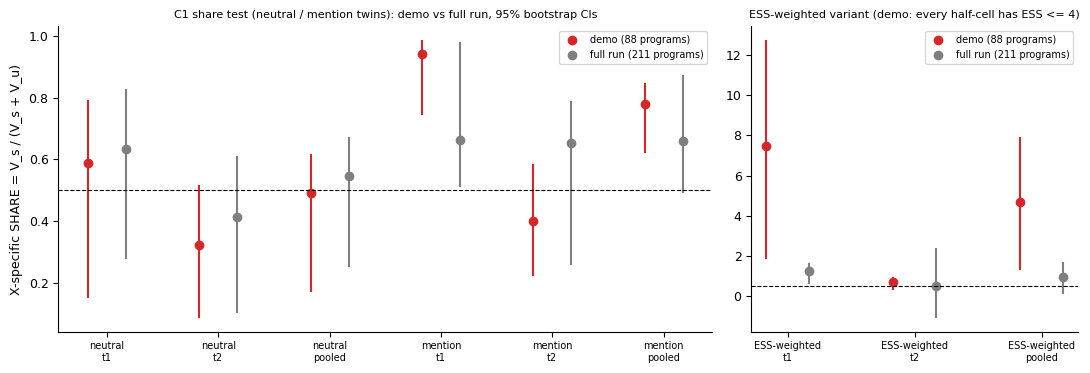

In [24]:
# Summary table: demo vs full run (data["full_run_reference"] holds the artifact's results/gate.json + c1.json numbers)
REF = data["full_run_reference"]
g, rg = gate_out["primary"], REF["gate"]
summary = [
    ("gate (a) mean S [0.3, 3]", f"{g['a']['mean_S']:.2f}", f"{rg['a']['mean_S']:.2f}"),
    ("gate (a) mean m_default >= 0.9", f"{g['a']['mean_m_default']:.2f} ({'PASS' if g['a']['pass'] else 'FAIL'})",
     f"{rg['a']['mean_m_default']:.2f} ({'PASS' if rg['a']['pass'] else 'FAIL'})"),
    ("gate (b) mean d_e >= 0.3 nats", f"{g['b']['mean_d_e']:.2f} ({'PASS' if g['b']['pass'] else 'FAIL'})",
     f"{rg['b']['mean_d_e']:.2f} ({'PASS' if rg['b']['pass'] else 'FAIL'})"),
    ("gate (c) argmax hits >= 80%", f"{g['c']['hits']}/{g['c']['n_clear']} ({'PASS' if g['c']['pass'] else 'FAIL'})",
     f"{rg['c']['hits']}/{rg['c']['n_clear']} ({'PASS' if rg['c']['pass'] else 'FAIL'})"),
    ("gate verdict", gate_out["verdict"], rg["verdict"]),
    ("gate: unscrubbed variant passes all", str(gate_out["sensitivity"]["unscrubbed"]["pass"]),
     str(rg["sensitivity"]["unscrubbed"]["pass"])),
    ("pooled Spearman implied vs realised", f"{g['pooled_spearman_implied_vs_realised']:.2f}",
     f"{rg['pooled_spearman_implied_vs_realised']:.2f}"),
]
for key, name in (("primary_neutral", "neutral twin"), ("reference_mention", "mention twin"), ("ess_weighted", "ESS-weighted")):
    d, r = out_c1[key], REF["c1"][key]
    for t in TASKS + ("pooled",):
        dd = d["pooled"] if t == "pooled" else d["tasks"][t]
        rr = r["pooled"] if t == "pooled" else r["tasks"][t]
        dci = dd["bootstrap"]["SHARE_ci"]
        summary.append((f"C1 SHARE {name} {t}",
                        f"{dd['share_point']['SHARE']:.2f} [{dci[0]:.2f}, {dci[1]:.2f}] {dd['branch']}",
                        f"{rr['SHARE']:.2f} [{rr['SHARE_ci'][0]:.2f}, {rr['SHARE_ci'][1]:.2f}] {rr['branch']}"))
ap, rap = out_c1["primary_neutral"]["aim_prime_veto"], REF["c1"]["primary_neutral"]["aim_prime_veto"]
summary.append(("AIM prime-and-veto (null p95, p)", f"{ap['aim']:.2f} ({ap['null_p95']:.2f}, p={ap['p']:.2f})",
                f"{rap['aim']:.2f} ({rap['null_p95']:.2f}, p={rap['p']:.2f})"))
for t in TASKS:
    le = out_c1["primary_neutral"]["tasks"][t]["ladder_exists"]
    rle = REF["c1"]["primary_neutral"]["ladder_exists"][t]
    summary.append((f"ladder exists {t} (mean centred cos)", f"{le['exists']} ({le['mean_pairwise_centred_cosine']:.2f})",
                    f"{rle['exists']} ({rle['mean_pairwise_centred_cosine']:.2f})"))
summary.append(("pooled branch robust (3 references)", str(out_c1["robust_pooled"]), str(REF["c1"]["robust_pooled"])))
print(pd.DataFrame(summary, columns=["quantity", f"demo (88 programs, N_BOOT={N_BOOT})", "full run (211 programs, N_BOOT=2000)"]
                   ).to_string(index=False))

# SHARE with 95% bootstrap CI: demo vs full run (CI drawn as a segment; the point can sit outside a small-N CI).
# The ESS-weighted variant gets its own panel: in the demo every half-cell has ESS <= 4, which changes its scale.
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2, 1]})
for ax, refs in ((axes[0], (("primary_neutral", "neutral"), ("reference_mention", "mention"))),
                 (axes[1], (("ess_weighted", "ESS-weighted"),))):
    labels, x0 = [], 0
    for key, name in refs:
        for t in TASKS + ("pooled",):
            dd = out_c1[key]["pooled"] if t == "pooled" else out_c1[key]["tasks"][t]
            rr = REF["c1"][key]["pooled"] if t == "pooled" else REF["c1"][key]["tasks"][t]
            for off, val, ci, col, lab in ((-0.17, dd["share_point"]["SHARE"], dd["bootstrap"]["SHARE_ci"], "tab:red",
                                            "demo (88 programs)"),
                                           (0.17, rr["SHARE"], rr["SHARE_ci"], "tab:gray", "full run (211 programs)")):
                ax.vlines(x0 + off, ci[0], ci[1], color=col, lw=1.5)
                ax.plot(x0 + off, val, "o", color=col, label=lab if x0 == 0 else None)
            labels.append(f"{name}\n{t}")
            x0 += 1
    ax.axhline(0.5, color="k", ls="--", lw=0.8)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=7)
    ax.legend(fontsize=7)
axes[0].set_ylabel("X-specific SHARE = V_s / (V_s + V_u)")
axes[0].set_title("C1 share test (neutral / mention twins): demo vs full run, 95% bootstrap CIs", fontsize=8)
axes[1].set_title("ESS-weighted variant (demo: every half-cell has ESS <= 4)", fontsize=8)
fig.tight_layout()
plt.show()

## Stage `outputs` (step 9): figures F1-F6 (`outputs.py`)

These are the artifact's six figures, drawn from this notebook's results. The figure functions are copied; each `savefig` to `figures/F*.png|pdf` is replaced by inline display, and F6 reads the in-memory cell table.

| Figure | Content |
|---|---|
| F1 | gate: implied vs realised shares and $d_e$ per event |
| F2 | centred gain heatmaps (ban x survivor) against the neutral and mention twins |
| F3 | per-row ladder vs X-specific sums of squares with their noise expectations |
| F4 | agreement (centred cosine) between the 8 generic perturbation profiles |
| F5 | the prime (mention minus neutral) and veto (ban minus mention) shares of each ban gain |
| F6 | ESS per half-cell |

The `method_out.json` builder (`build_method_out`) and the frozen-profile writer (`freeze.py`) only write files; they are not reproduced.

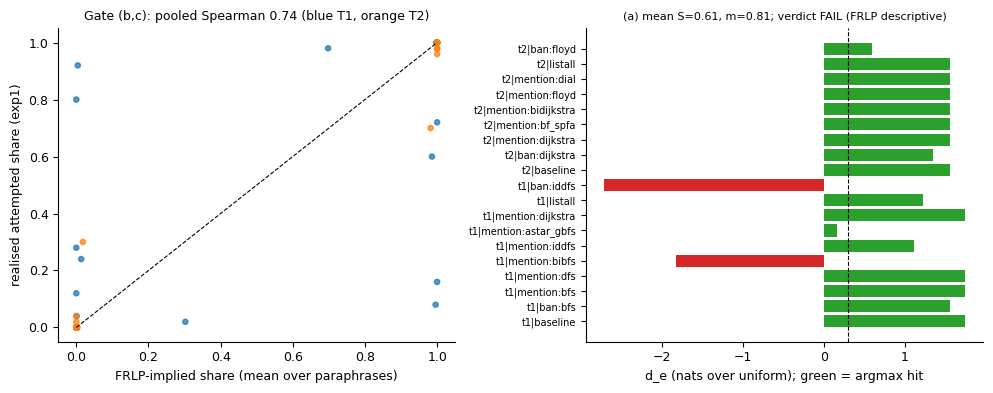

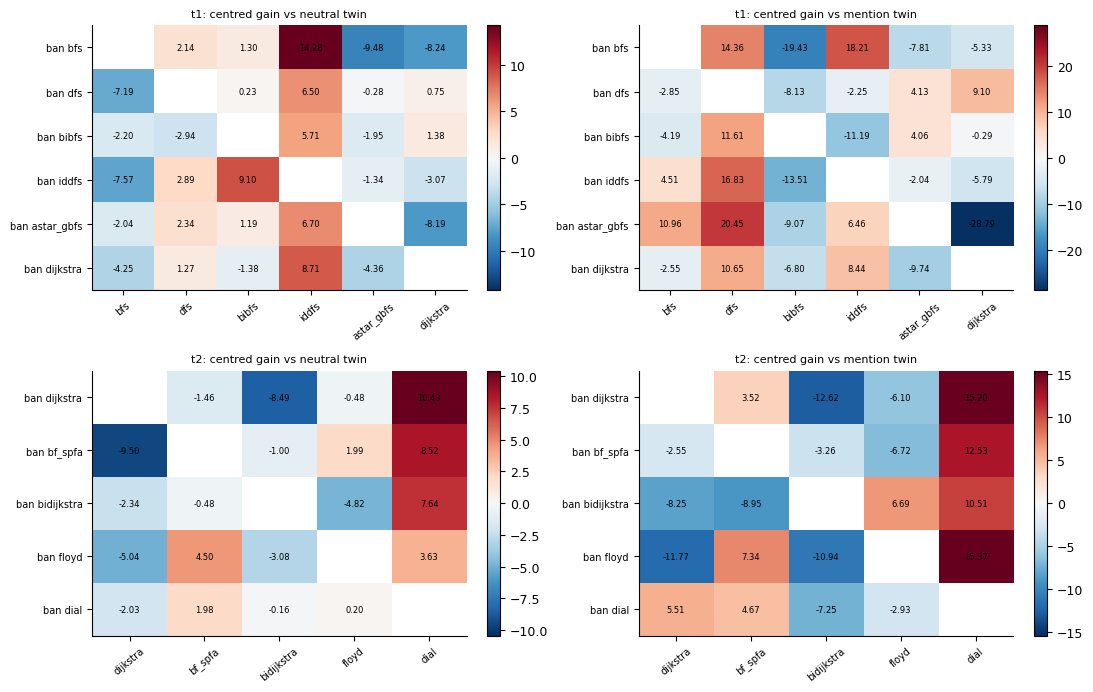

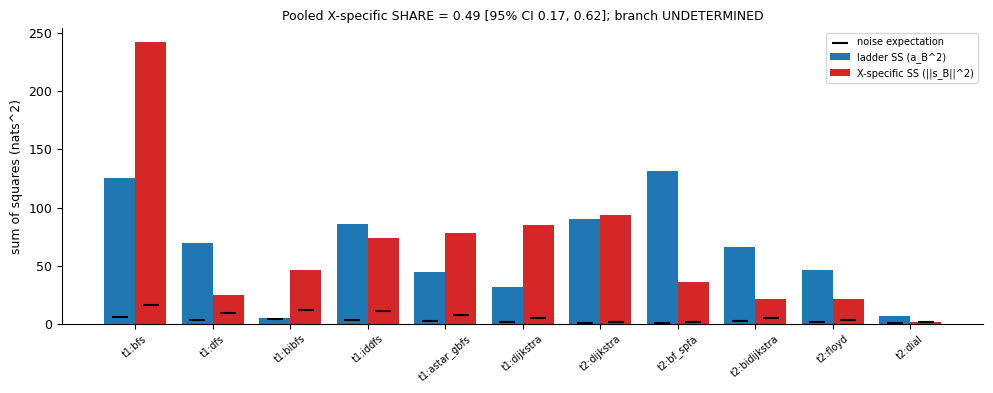

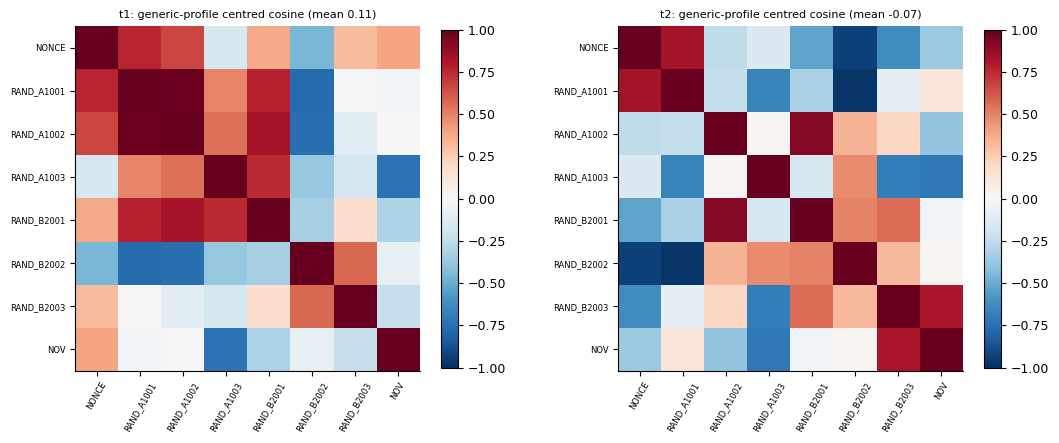

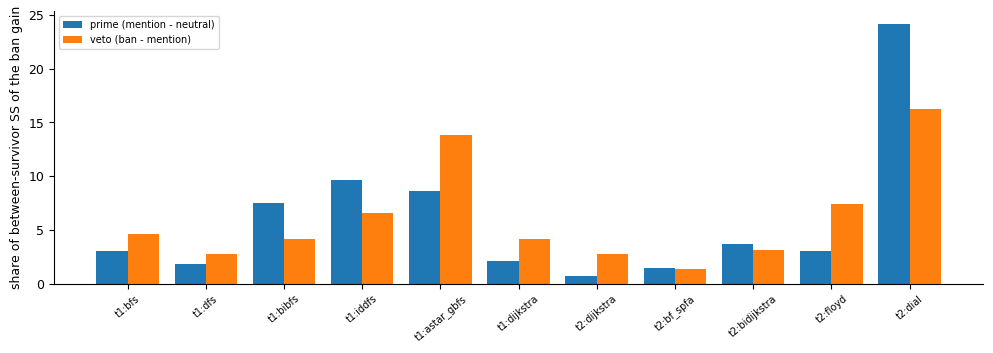

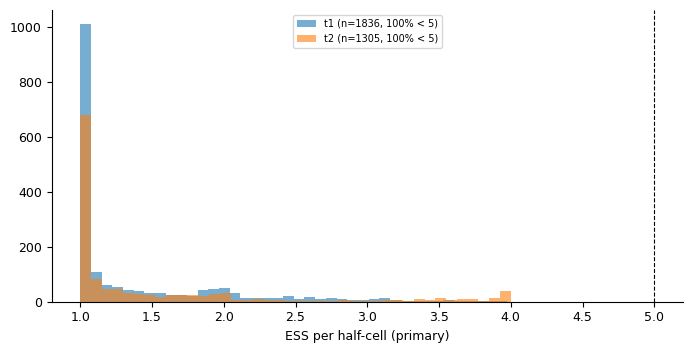

In [25]:
# ---- src/outputs.py: figures (copied; savefig to figures/ replaced by plt.show()) ----
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})


def fig_gate(gate: dict[str, Any]) -> None:
    ev = gate["primary"]["events"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    xs, ys, cs = [], [], []
    for e in ev:
        n = sum(v for v in e["realised_allowed"].values()) or 1
        for j, q in e["implied_mean"].items():
            xs.append(q)
            ys.append(e["realised_allowed"].get(j, 0) / n)
            cs.append("tab:blue" if e["event_id"].startswith("t1") else "tab:orange")
    axes[0].scatter(xs, ys, c=cs, s=14, alpha=0.75)
    axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[0].set_xlabel("FRLP-implied share (mean over paraphrases)")
    axes[0].set_ylabel("realised attempted share (exp1)")
    axes[0].set_title(f"Gate (b,c): pooled Spearman {gate['primary']['pooled_spearman_implied_vs_realised']:.2f} "
                      "(blue T1, orange T2)", fontsize=9)
    names = [e["event_id"] for e in ev]
    d = [e["d_e"] for e in ev]
    axes[1].barh(range(len(names)), d, color=["tab:green" if e["hit"] else "tab:red" for e in ev])
    axes[1].axvline(0.3, color="k", ls="--", lw=0.8)
    axes[1].set_yticks(range(len(names)))
    axes[1].set_yticklabels(names, fontsize=7)
    axes[1].set_xlabel("d_e (nats over uniform); green = argmax hit")
    a = gate["primary"]["a"]
    axes[1].set_title(f"(a) mean S={a['mean_S']:.2f}, m={a['mean_m_default']:.2f}; verdict {gate['verdict']}",
                      fontsize=8)
    fig.tight_layout()
    plt.show()          # was: fig.savefig(FIGS / "F1_gate.png", dpi=160); fig.savefig(FIGS / "F1_gate.pdf"); plt.close(fig)


def fig_heatmaps(c1: dict[str, Any]) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ci, key in enumerate(("primary_neutral", "reference_mention")):
        for ti, t in enumerate(TASKS):
            ax = axes[ti, ci]
            rows = c1[key]["tasks"][t]["rows"]
            js_ = c1[key]["tasks"][t]["measurable"]
            M = np.full((len(MODES[t]), len(js_)), np.nan)
            for bi, B in enumerate(MODES[t]):
                if B in rows:
                    for j, v in rows[B]["Gbar"].items():
                        M[bi, js_.index(j)] = v
            lim = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1
            im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
            ax.set_xticks(range(len(js_)))
            ax.set_xticklabels(js_, rotation=40, fontsize=7)
            ax.set_yticks(range(len(MODES[t])))
            ax.set_yticklabels([f"ban {b}" for b in MODES[t]], fontsize=7)
            for (i, k), v in np.ndenumerate(M):
                if np.isfinite(v):
                    ax.text(k, i, f"{v:.2f}", ha="center", va="center", fontsize=6)
            ax.set_title(f"{t}: centred gain vs {'neutral' if ci == 0 else 'mention'} twin", fontsize=8)
            fig.colorbar(im, ax=ax, fraction=0.04)
    fig.tight_layout()
    plt.show()          # was: savefig F2_gain_heatmaps.png/.pdf


def fig_share(c1: dict[str, Any]) -> None:
    P = c1["primary_neutral"]
    labels, lad, spec, nu, ns = [], [], [], [], []
    for t in TASKS:
        for B, r in P["tasks"][t]["rows"].items():
            labels.append(f"{t}:{B}")
            lad.append(r["a2"])
            spec.append(r["ss_s"])
            nu.append(r["N_u"])
            ns.append(r["N_s"])
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - 0.2, lad, 0.4, label="ladder SS (a_B^2)", color="tab:blue")
    ax.bar(x + 0.2, spec, 0.4, label="X-specific SS (||s_B||^2)", color="tab:red")
    ax.scatter(x - 0.2, nu, marker="_", color="k", s=120, label="noise expectation")
    ax.scatter(x + 0.2, ns, marker="_", color="k", s=120)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=40, fontsize=7)
    pb = P["pooled"].get("bootstrap", {})
    sp = P["pooled"]["share_point"]
    ci = pb.get("SHARE_ci", [math.nan, math.nan])
    ax.set_title(f"Pooled X-specific SHARE = {sp['SHARE']:.2f} [95% CI {ci[0]:.2f}, {ci[1]:.2f}]; "
                 f"branch {P['pooled'].get('branch')}", fontsize=9)
    ax.set_ylabel("sum of squares (nats^2)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()          # was: savefig F3_share.png/.pdf


def fig_cos(c1: dict[str, Any]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, t in zip(axes, TASKS):
        le = c1["primary_neutral"]["tasks"][t].get("ladder_exists", {})
        mat = le.get("matrix", {})
        names = list(mat)
        M = np.array([[mat[a][b] for b in names] for a in names]) if names else np.zeros((1, 1))
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels(names, rotation=60, fontsize=6)
        ax.set_yticks(range(len(names)))
        ax.set_yticklabels(names, fontsize=6)
        ax.set_title(f"{t}: generic-profile centred cosine (mean {le.get('mean_pairwise_centred_cosine', math.nan):.2f})",
                     fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.04)
    fig.tight_layout()
    plt.show()          # was: savefig F4_generic_cosines.png/.pdf


def fig_prime_veto(c1: dict[str, Any]) -> None:
    P = c1["primary_neutral"]
    labels, pr, ve = [], [], []
    for t in TASKS:
        for B, x in P["tasks"][t].get("extras", {}).items():
            labels.append(f"{t}:{B}")
            pr.append(x["prime_share_of_ss"])
            ve.append(x["veto_share_of_ss"])
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.bar(x - 0.2, pr, 0.4, label="prime (mention - neutral)")
    ax.bar(x + 0.2, ve, 0.4, label="veto (ban - mention)")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=40, fontsize=7)
    ax.set_ylabel("share of between-survivor SS of the ban gain")
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()          # was: savefig F5_prime_veto.png/.pdf


def fig_ess(rows: list[dict[str, Any]]) -> None:
    # was: rows = read_jsonl(RESULTS / "frlp_cells.jsonl")
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for t, c in (("t1", "tab:blue"), ("t2", "tab:orange")):
        e = [r["ess"] for r in rows if r["task"] == t and r["variant"] == "primary" and r["half"] != "all"
             and r["ess"] is not None]
        if e:
            ax.hist(e, bins=40, alpha=0.6, label=f"{t} (n={len(e)}, {np.mean(np.array(e) < 5):.0%} < 5)", color=c)
    ax.axvline(5, color="k", ls="--", lw=0.8)
    ax.set_xlabel("ESS per half-cell (primary)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()          # was: savefig F6_ess.png/.pdf


# outputs.main (figure part)
for fn, arg in ((fig_gate, gate_out), (fig_heatmaps, out_c1), (fig_share, out_c1), (fig_cos, out_c1),
                (fig_prime_veto, out_c1)):
    if arg is not None:
        try:
            fn(arg)
        except (KeyError, ValueError, TypeError) as e:
            logger.error(f"figure {fn.__name__} failed: {e}")
try:
    fig_ess(cell_rows)
except (KeyError, ValueError, TypeError) as e:
    logger.error(f"figure ess failed: {e}")

## Take-aways

**What the demo reproduces** (88 of 211 programs, the original bootstrap and permutation sizes):

- **Gate.** FRLP fails calibration (a) on the name-scrubbed programs: the mean default-mode share is m = 0.81 against the 0.9 bar (full run 0.83). Discrimination (b, 1.02 nats) and argmax (c, 17/19) pass. The *unscrubbed* variant passes all three criteria, as in the full run. This supports the artifact's diagnosis that scrubbing names out of the programs, not the estimator, breaks calibration.
- **C1 with the primary (neutral-twin) reference.** The test stays UNDETERMINED. The pooled X-specific SHARE is 0.49 [0.17, 0.62] (full run 0.55 [0.25, 0.67]), and the CI straddles 0.5.
- **Neither rival account fits.** There is no aimed substitute: AIM -0.02, null 95th percentile 0.21, p = 0.56. There is no coherent generic ladder: the mean centred cosine of the 8 generic profiles is 0.11 on T1 and -0.07 on T2, below the 0.5 bar.

**Where the small subset diverges.** With the mention-twin reference the demo's pooled SHARE CI lies above 0.5 (0.78 [0.62, 0.85], X-SPECIFIC-UNAIMED), while the full run's straddles 0.5. The ESS-weighted variant is degenerate here (ESS of at most 4). So the demo's pooled branch is not robust across references, whereas the full run's was. Cells built from 4 programs per half are high-variance.

**The artifact's recommendation:** the confirmation bench should score unscrubbed (or name-matched) programs.